# IMF Country Report → LLM Text-to-Dashboard Pipeline
## Canada — 2024 Article IV Consultation (IMF Country Report No. 24/128)

**Module:** Data Analysis with AI — Assignment 1 (LLM coding case study)
**Allocation:** SRN 24135630 → Canada, report years 2024–2025 → *Canada: 2024 Article IV Consultation — Press Release; and Staff Report* (IMF Country Report No. 24/128, published 16 July 2024). This is the latest Article IV staff report published within the 2024–2025 volumes; the 2025 Article IV was only published in the 2026 volume (CR 26/12, January 2026), and the 2025 volume contains only an FSAP stability assessment, which is not an Article IV report.

### What this notebook does
| Stage | Task | Main techniques |
|---|---|---|
| 1 | PDF processing & summarisation | `pypdf` extraction, rule-based cleaning, section segmentation, token-aware sentence chunking, batched section summaries, executive summary, **LLM-as-a-Judge** audit + deterministic numeric-grounding checks |
| 3* | RAG index | `sentence-transformers` (BAAI/bge-small-en-v1.5) dense embeddings + `faiss.IndexFlatL2` (*built before Task 2 because indicator extraction is retrieval-grounded*) |
| 2 | Themes, indicators, structured output | lexicon + LLM thematic classification (7 themes), strengths / vulnerabilities with verified evidence quotes, schema-constrained indicator JSON (3 configurations compared), fallback capture, temporal trend extraction cross-checked against the report's tables |
| 3 | RAG grounding & retrieval | closed-book vs single-query RAG vs **multi-query RAG (extension)**, blind judge scoring |
| 4 | Visualisation | `pd.melt` tidy transforms, 6-panel executive dashboard + individual 300-dpi figures |

### How to run (marker instructions)
1. **Colab:** `Runtime → Run all`. The setup cell clones the GitHub repository (PDF + LLM cache) automatically.
2. **API key (optional):** add a Colab secret named `GEMINI_API_KEY` (🔑 icon in the left sidebar) and enable notebook access.
   *Without a key the notebook replays every LLM response from the committed cache (`cache/llm_cache.json`), so it still runs end-to-end and reproduces every number in the report.*
3. All outputs are written to `outputs/` (JSON) and `outputs/figures/` (PNG, 300 dpi).

> **Human oversight.** Every LLM output in this notebook is checked twice: by a *second* LLM acting as judge, and by deterministic Python checks (evidence quotes must exist in the source, numbers must match the report's tables, values must be inside plausible ranges, and indicator values are scored against a human-verified gold set with page references).

## 0. Setup
### 0.1 Environment & dependencies
Installs only what Colab does not already provide. Running locally, install `requirements.txt` instead.

In [1]:
import os, sys, subprocess, importlib

IN_COLAB = "google.colab" in sys.modules

REQUIRED = {  # import name -> pip name
    "pypdf": "pypdf==7.0.0",   # pinned: identical text extraction => identical prompts => committed cache hits
    "faiss": "faiss-cpu>=1.8",
    "sentence_transformers": "sentence-transformers>=3.0",
    "google.genai": "google-genai>=1.30",
    "pydantic": "pydantic>=2.6",
}

def ensure_packages(packages: dict) -> None:
    """pip-install any package that cannot be imported (keeps re-runs fast)."""
    missing = []
    for mod, pip_name in packages.items():
        try:
            importlib.import_module(mod)
        except ImportError:
            missing.append(pip_name)
    try:
        import pypdf
        if pypdf.__version__ != "7.0.0":
            missing.append(packages["pypdf"])
    except ImportError:
        pass
    if missing:
        print("Installing:", missing)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    else:
        print("All dependencies already available.")

ensure_packages(REQUIRED)

C:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All dependencies already available.


In [2]:
import json, re, time, math, hashlib, random, unicodedata, textwrap, difflib
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Optional, List, Dict, Any

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pypdf import PdfReader
from pydantic import BaseModel, Field, ValidationError, ConfigDict

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| Colab:", IN_COLAB)

Python 3.10.11 | pandas 2.3.3 | Colab: False


### 0.2 Configuration
All tunable parameters live here — nothing below this cell hard-codes a path, model or threshold.

**Design choices (justified in the report):**
* **Chunk size 400 tokens, 50-token overlap**, measured with the *embedding model's own tokenizer*. `bge-small-en-v1.5` accepts 512 tokens, so a 400-token chunk is embedded **without truncation** (the popular `all-MiniLM-L6-v2` silently truncates at 256 tokens, which would discard ~40 % of each chunk).
* **Two different Gemini models**: an *extractor* and a *judge*. The judge is deliberately a different model so it does not simply agree with its own outputs (self-preference bias). A third *challenger* model is used for the model-comparison benchmark.
* Model names are resolved **at run time** from preference lists, because Gemini model availability changes frequently.

In [3]:
@dataclass
class Config:
    # --- document ---
    country: str = "Canada"
    report_title: str = "Canada: 2024 Article IV Consultation-Press Release; and Staff Report"
    report_id: str = "IMF Country Report No. 24/128"
    consultation_year: int = 2024
    pdf_filename: str = "canada_2024_article_iv.pdf"
    pdf_url: str = "https://www.imf.org/-/media/files/publications/cr/2024/english/1canea2024001.pdf"
    repo_url: str = "https://github.com/ds25abd/imf-llm-canada.git"
    first_projection_year: int = 2024       # the indicators table marks 2023 as "Est." and 2024 onwards as "Proj."
    # --- chunking ---
    embed_model: str = "BAAI/bge-small-en-v1.5"
    chunk_tokens: int = 400
    overlap_tokens: int = 50
    min_chunk_tokens: int = 40
    # --- retrieval ---
    top_k: int = 5
    multi_query_variants: int = 4
    rrf_k: int = 60                          # reciprocal-rank-fusion constant
    multi_query_final_k: int = 8
    # --- LLMs (first available model in each list is used) ---
    # free tier = 20 requests/day per model, so the pipeline spreads its ~35 calls over three models
    extractor_prefs: tuple = ("gemini-3.5-flash", "gemini-3.7-flash", "gemini-3-flash", "gemini-3-flash-preview",
                              "gemini-2.5-flash", "gemini-flash-latest")
    challenger_prefs: tuple = ("gemini-3.5-flash-lite", "gemini-3-flash-lite", "gemini-3-flash-lite-preview",
                               "gemini-2.5-flash-lite", "gemini-flash-lite-latest")
    judge_prefs: tuple = ("gemini-3.8-flash", "gemini-3.5-pro", "gemini-3-pro-preview", "gemini-2.5-pro",
                          "gemini-3.5-flash", "gemini-3-flash-preview", "gemini-2.5-flash", "gemini-flash-latest")
    temperature: float = 0.0
    min_seconds_between_calls: float = 4.5   # stays under free-tier requests-per-minute limits
    max_retries: int = 10                    # 503 "model overloaded" errors are transient: wait them out
    summary_word_limit: int = 100
    batch_token_budget: int = 60000          # max source tokens per batched call (fewer calls vs. free-tier daily quota)
    # --- fallback ---
    fallback_value: Optional[float] = None   # in-memory marker for "not reliably extracted"
    json_fallback_value: float = -1.0        # value written to core_indicators.json (keeps every field a float)

CFG = Config()

# Locate the project root (works locally, in a cloned repo, and in Colab).
def find_project_root() -> Path:
    for cand in [Path.cwd(), Path.cwd() / "imf-llm-canada", Path("/content/imf-llm-canada")]:
        if (cand / "data").exists() or (cand / "notebook_src.py").exists():
            return cand
    return Path.cwd()

ROOT = find_project_root()

def bootstrap_repository(root: Path) -> Path:
    """In Colab, clone the repo (PDF + LLM cache) if the data folder is not present."""
    if (root / "data" / CFG.pdf_filename).exists():
        return root
    if IN_COLAB:
        target = Path("/content/imf-llm-canada")
        if not target.exists():
            subprocess.run(["git", "clone", "-q", CFG.repo_url, str(target)], check=False)
        if (target / "data").exists():
            return target
    return root

ROOT = bootstrap_repository(ROOT)
os.chdir(ROOT)
DATA_DIR, OUT_DIR, FIG_DIR, CACHE_DIR = (ROOT / d for d in ("data", "outputs", "outputs/figures", "cache"))
for d in (DATA_DIR, OUT_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

def save_json(obj: Any, name: str) -> Path:
    """Write machine-readable output to outputs/<name>."""
    path = OUT_DIR / name
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    return path

Project root: C:\Users\Admin\imf-llm-canada


### 0.3 Obtain the PDF
Order of preference: committed copy in `data/` → direct download from the IMF → manual upload (Colab).

In [4]:
def get_report_pdf(cfg: Config) -> Path:
    path = DATA_DIR / cfg.pdf_filename
    if path.exists() and path.stat().st_size > 100_000:
        return path
    try:
        import urllib.request
        req = urllib.request.Request(cfg.pdf_url, headers={"User-Agent": "imf-llm-coursework"})
        with urllib.request.urlopen(req, timeout=60) as r:
            content = r.read()
        if content[:4] == b"%PDF":
            path.write_bytes(content)
            return path
        print("IMF server did not return a PDF (bot protection) – falling back to upload.")
    except Exception as e:
        print("Download failed:", e)
    if IN_COLAB:
        from google.colab import files
        uploaded = files.upload()
        name = next(iter(uploaded))
        path.write_bytes(uploaded[name])
        return path
    raise FileNotFoundError(f"Place the report at {path}")

PDF_PATH = get_report_pdf(CFG)
print(PDF_PATH, f"{PDF_PATH.stat().st_size/1e6:.1f} MB")

C:\Users\Admin\imf-llm-canada\data\canada_2024_article_iv.pdf 10.8 MB


### 0.4 LLM layer: model resolution, disk cache, retries, schema enforcement
* **Disk cache** — every response is stored in `cache/llm_cache.json` keyed by a SHA-256 hash of *(model, system instruction, prompt, schema, temperature)*. Re-runs cost zero API calls and are fully reproducible; the original latency is cached too, so the benchmark remains comparable.
* **Throttling + exponential back-off** on HTTP 429/5xx (free-tier rate limits).
* **Schema enforcement** — structured calls send a JSON Schema (`response_json_schema`) *and* validate the reply with Pydantic; if validation fails, a single *repair* prompt is issued with the validation error.
* **Call log** — every call (task, model, latency, cache hit, tokens) is recorded for the benchmark.

In [5]:
def get_api_key() -> Optional[str]:
    if IN_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("GEMINI_API_KEY")
        except Exception:
            pass
    env_file = ROOT / ".env"            # local runs: a git-ignored file containing GEMINI_API_KEY=...
    if env_file.exists():
        for line in env_file.read_text().splitlines():
            if line.strip().startswith("GEMINI_API_KEY="):
                return line.split("=", 1)[1].strip().strip('"\'')
    return os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")

API_KEY = get_api_key()
CACHE_PATH = CACHE_DIR / "llm_cache.json"
MODELS_PATH = CACHE_DIR / "resolved_models.json"
FORCE_RESOLVE_MODELS = False   # True = probe the API again and pick new models (invalidates the cache)


class LLMCache:
    """Tiny JSON-file cache. Written after every new response so an interrupted run loses nothing."""
    def __init__(self, path: Path):
        self.path = path
        self.data = json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}
    @staticmethod
    def key(*parts) -> str:
        return hashlib.sha256("\x1f".join(map(str, parts)).encode("utf-8")).hexdigest()
    def get(self, k): return self.data.get(k)
    def put(self, k, v):
        self.data[k] = v
        tmp = self.path.with_suffix(".tmp")
        tmp.write_text(json.dumps(self.data, ensure_ascii=False, indent=1), encoding="utf-8")
        tmp.replace(self.path)


class GeminiLLM:
    def __init__(self, api_key: Optional[str], cfg: Config):
        self.cfg, self.cache, self.log = cfg, LLMCache(CACHE_PATH), []
        self._last_call = 0.0
        self.client = None
        if api_key:
            from google import genai
            self.client = genai.Client(api_key=api_key)

    # ---------- model resolution ----------
    def _available(self) -> set:
        names = set()
        for m in self.client.models.list():
            actions = getattr(m, "supported_actions", None) or []
            if not actions or "generateContent" in actions:
                names.add(m.name.replace("models/", ""))
        return names

    def _probe(self, model: str) -> bool:
        """A 1-token request confirms the key actually has quota for this model."""
        try:
            self.client.models.generate_content(model=model, contents="Reply with OK.")
            return True
        except Exception as e:
            print(f"   probe failed for {model}: {str(e)[:120]}")
            return False

    def resolve_models(self) -> Dict[str, str]:
        if self.client is None:
            if MODELS_PATH.exists():
                models = json.loads(MODELS_PATH.read_text())
                print("No API key – replaying cached responses for models:", models)
                return models
            raise RuntimeError("No GEMINI_API_KEY and no cache found. Add the key as a Colab secret.")
        if MODELS_PATH.exists() and not FORCE_RESOLVE_MODELS:
            models = json.loads(MODELS_PATH.read_text())
            print("Re-using previously resolved models (set FORCE_RESOLVE_MODELS=True to re-probe):", models)
            return models
        available = self._available()
        chosen = {}
        for role, prefs in [("extractor", self.cfg.extractor_prefs),
                            ("challenger", self.cfg.challenger_prefs),
                            ("judge", self.cfg.judge_prefs)]:
            used = set(chosen.values())
            for m in prefs:
                if m in available and m not in used and self._probe(m):
                    chosen[role] = m
                    break
            if role not in chosen:
                raise RuntimeError(f"No usable model for role '{role}'. Edit Config.{role}_prefs. "
                                   f"Available: {sorted(a for a in available if 'gemini' in a)}")
        MODELS_PATH.write_text(json.dumps(chosen, indent=2))
        return chosen

    # ---------- core call ----------
    def _throttle(self):
        wait = self.cfg.min_seconds_between_calls - (time.time() - self._last_call)
        if wait > 0:
            time.sleep(wait)
        self._last_call = time.time()

    def _raw_generate(self, model, prompt, system, json_schema):
        from google.genai import types
        kwargs = dict(temperature=self.cfg.temperature)
        if system:
            kwargs["system_instruction"] = system
        if json_schema is not None:
            kwargs["response_mime_type"] = "application/json"
            kwargs["response_json_schema"] = json_schema
        resp = self.client.models.generate_content(
            model=model, contents=prompt, config=types.GenerateContentConfig(**kwargs))
        usage = getattr(resp, "usage_metadata", None)
        return resp.text or "", {
            "prompt_tokens": getattr(usage, "prompt_token_count", None),
            "output_tokens": getattr(usage, "candidates_token_count", None)}

    def generate(self, prompt: str, model: str, task: str, system: Optional[str] = None,
                 json_schema: Optional[dict] = None) -> str:
        k = self.cache.key(model, system, prompt, json.dumps(json_schema, sort_keys=True), self.cfg.temperature)
        hit = self.cache.get(k)
        if hit is not None:
            self.log.append({"task": task, "model": model, "cached": True, **hit["meta"]})
            return hit["text"]
        if self.client is None:
            raise RuntimeError(f"Cache miss for task '{task}' and no API key available.")
        for attempt in range(self.cfg.max_retries):
            self._throttle()
            t0 = time.time()
            try:
                text, usage = self._raw_generate(model, prompt, system, json_schema)
                meta = {"latency_s": round(time.time() - t0, 3), **usage}
                self.cache.put(k, {"text": text, "meta": meta, "task": task, "model": model})
                self.log.append({"task": task, "model": model, "cached": False, **meta})
                return text
            except Exception as e:
                code = getattr(e, "code", None)
                msg = str(e)
                if code == 429 and "PerDay" in msg:
                    raise RuntimeError(f"[{task}] daily free-tier quota for {model} is used up. Re-run later: every "
                                       "completed call is cached, so the run resumes where it stopped.") from e
                # transient: rate limits, server errors, and dropped connections (httpx RemoteProtocolError,
                # timeouts) that carry no HTTP status code
                network = type(e).__name__ in ("RemoteProtocolError", "ConnectError", "ReadTimeout", "ReadError",
                                               "WriteError", "ConnectTimeout", "TimeoutException")
                if code in (429, 500, 502, 503, 504) or "RESOURCE_EXHAUSTED" in msg or network:
                    m = re.search(r"retry in ([\d.]+)s", msg)
                    delay = float(m.group(1)) + 1 if m else min(60, 5 * 2 ** attempt)
                    print(f"   [{task}] {code} – retrying in {delay:.0f}s (attempt {attempt+1})")
                    time.sleep(delay)
                    continue
                raise
        raise RuntimeError(f"[{task}] failed after {self.cfg.max_retries} retries")

    # ---------- structured call ----------
    def generate_structured(self, prompt: str, model: str, task: str, schema_model: type,
                            system: Optional[str] = None, enforce_schema: bool = True):
        """Returns (validated pydantic object | None, raw_text, diagnostics)."""
        schema = schema_model.model_json_schema() if enforce_schema else None
        try:
            raw = self.generate(prompt, model, task, system, schema)
        except Exception as e:
            if getattr(e, "code", None) != 400 or schema is None:
                raise
            # some model versions reject parts of a JSON Schema: fall back to schema-in-prompt
            print(f"   [{task}] schema rejected by API ({str(e)[:80]}) – sending schema in the prompt instead")
            prompt = f"{prompt}\n\nReturn ONLY JSON matching this JSON Schema:\n{json.dumps(schema)}"
            schema = None
            raw = self.generate(prompt, model, task, system, None)
        diag = {"json_valid": False, "schema_valid": False, "repaired": False}
        obj, err = _parse_and_validate(raw, schema_model, diag)
        if obj is None and enforce_schema:
            repair = (f"{prompt}\n\nYour previous reply failed validation with this error:\n{err}\n"
                      f"Return ONLY corrected JSON that matches the schema.")
            raw = self.generate(repair, model, task + ":repair", system, schema)
            diag["repaired"] = True
            obj, err = _parse_and_validate(raw, schema_model, diag)
        diag["error"] = err
        return obj, raw, diag


def extract_json_text(raw: str) -> str:
    """Strip markdown fences / prose that generic prompts often wrap around JSON."""
    raw = raw.strip()
    m = re.search(r"```(?:json)?\s*(.*?)```", raw, re.S)
    if m:
        raw = m.group(1).strip()
    start = min([i for i in (raw.find("{"), raw.find("[")) if i >= 0], default=0)
    return raw[start:]


def _parse_and_validate(raw: str, schema_model: type, diag: dict):
    try:
        data = json.loads(extract_json_text(raw))
        diag["json_valid"] = True
    except json.JSONDecodeError as e:
        return None, f"JSONDecodeError: {e}"
    try:
        obj = schema_model.model_validate(data)
        diag["schema_valid"] = True
        return obj, None
    except ValidationError as e:
        return None, str(e)[:800]


LLM = GeminiLLM(API_KEY, CFG)
MODELS = LLM.resolve_models()
EXTRACTOR, CHALLENGER, JUDGE = MODELS["extractor"], MODELS["challenger"], MODELS["judge"]
print("Extractor:", EXTRACTOR, "| Challenger:", CHALLENGER, "| Judge:", JUDGE)

Re-using previously resolved models (set FORCE_RESOLVE_MODELS=True to re-probe): {'extractor': 'gemini-3.5-flash', 'challenger': 'gemini-3.5-flash-lite', 'judge': 'gemini-3.8-flash'}
Extractor: gemini-3.5-flash | Challenger: gemini-3.5-flash-lite | Judge: gemini-3.8-flash


---
## Task 1 — PDF processing pipeline & summarisation
### 1.1 Extraction
`pypdf` extracts the text layer page by page. The report has a native text layer (no OCR needed). We keep the page number with every line so every downstream output can cite a page.

In [6]:
def extract_pages(pdf_path: Path) -> List[str]:
    reader = PdfReader(str(pdf_path))
    return [(p.extract_text() or "") for p in reader.pages]

RAW_PAGES = extract_pages(PDF_PATH)
raw_chars = sum(map(len, RAW_PAGES))
print(f"{len(RAW_PAGES)} pages, {raw_chars:,} raw characters")
print("--- raw sample (PDF page 11) ---\n", RAW_PAGES[10][:600])

129 pages, 295,115 raw characters
--- raw sample (PDF page 11) ---
 CANADA 
INTERNATIONAL MONETARY FUND 7 
10.      The fiscal stance turned slightly expansionary in 2023, although within the context of 
low general government deficits and debt relative to peers. Reflecting mainly rising spending by 
provincial and local governments, the general government cyclically adjusted deficit widened from 
0.2 to 0.6 percent of potential GDP in calendar 2023. That said, and despite pandemic-related fiscal 
support, Canada has some fiscal space, with general government gross debt remaining relatively 
moderate compared to other G7 countries and low overall risks of sove


### 1.2 Cleaning
Artifacts observed in the raw text and the rule that removes each one:

| Artifact | Example | Fix |
|---|---|---|
| Running header / footer | `CANADA`, `24 INTERNATIONAL MONETARY FUND` | regex line filter |
| Table-of-contents leaders | `CONTEXT ______ 5` | drop lines with `___` |
| Hard line breaks mid-sentence | `…to the\nlower end…` | paragraph re-flow (joins lines unless a new numbered paragraph, bullet or heading starts) |
| Vulgar fractions | `2¼ percent` | → `2.25 percent` (**critical**: Unicode NFKC would turn `2¼` into `21⁄4`, i.e. a policy rate of "21") |
| Footnote markers glued to headings | `Box 1. Exchange Rate Pass-Through in Canada1` | trailing-digit strip on headings |
| Ligatures, non-breaking spaces, bullets | `ﬁ`, `\xa0`, `•` | normalisation table |

Pages whose first content line is `Figure …` or `Table …` are tagged so that chart-axis noise is kept out of summaries and theme counts, and so that **tables keep their row structure** (one row per line) for indicator and trend extraction.

In [7]:
FRACTIONS = {"¼": ".25", "½": ".5", "¾": ".75", "⅓": ".33", "⅔": ".67", "⅛": ".125"}
CHAR_FIXES = {" ": " ", " ": " ", "ﬁ": "fi", "ﬂ": "fl", "‐": "-", "‑": "-",
              "‒": "-", "−": "-", "―": "—", "": "•", "▪": "•", "●": "•"}

def fix_characters(text: str) -> str:
    for a, b in CHAR_FIXES.items():
        text = text.replace(a, b)
    # "2¼" -> "2.25", a lone "¾ percent" -> "0.75 percent"
    for frac, dec in FRACTIONS.items():
        text = re.sub(rf"(\d){frac}", rf"\g<1>{dec}", text)
        text = re.sub(rf"(?<![\d.]){frac}", f"0{dec}", text)
    return text

def header_footer_patterns(country: str) -> List[re.Pattern]:
    c = re.escape(country.upper())
    return [re.compile(p) for p in [
        rf"^{c}$",
        r"^\d{1,3}\s+INTERNATIONAL MONETARY FUND$",
        r"^INTERNATIONAL MONETARY FUND\s+\d{1,3}$",
        r"^\d{1,3}$",                                   # bare page numbers
        r"^©.*International Monetary Fund$",
        r".*_{4,}.*",                                    # TOC leader lines
    ]]

NUMERIC_ROW = re.compile(r"(?:\s-?\d[\d,]*\.?\d*){4,}\s*$")    # a row ending in >= 4 numbers

def classify_page(lines: List[str]) -> str:
    first = next((l for l in lines if l), "")
    if re.match(r"^(Annex [IVX]+\.\s+)?Figure \d+\.", first):
        return "figure"
    if re.match(r"^(Annex [IVX]+\.\s+)?Table( \d+)?\.", first):
        return "table"
    # untitled statistical tables (e.g. the press release's "Selected Economic Indicators"):
    # many lines that end in a run of numbers
    numeric = sum(bool(NUMERIC_ROW.search(l)) for l in lines)
    if numeric >= 8 and numeric / max(len(lines), 1) >= 0.35:
        return "table"
    return "text"

HEADING_RE = re.compile(
    r"^(KEY ISSUES|CONTEXT|RECENT (ECONOMIC )?(OUTCOMES|DEVELOPMENTS)|OUTLOOK AND RISKS|POLICY DISCUSSIONS|"
    r"STAFF APPRAISAL|FUND RELATIONS|[A-H]\.\s+[A-Z].{3,90}|Box \d+\..*|Annex [IVX]+\..*|Figure \d+\..*|Table \d+\..*)$")

def reflow(lines: List[str]) -> str:
    """Join hard-wrapped lines into paragraphs; keep breaks before numbered paragraphs, bullets and headings."""
    paras, cur = [], ""
    for ln in lines:
        # a heading-like line only counts as a heading if the previous text ended a sentence;
        # otherwise it is a wrapped cross-reference such as "...presented in\nAnnex XII. Eliminating ..."
        is_heading = bool(HEADING_RE.match(ln)) and (ln.isupper() or not cur or cur.isupper()
                                                     or cur.rstrip().endswith((".", ":", ")")))
        new_block = (re.match(r"^\d{1,2}\.\s{2,}", ln) or ln.startswith("•") or is_heading)
        if new_block and cur:
            paras.append(cur); cur = ""
        if cur.endswith("-") and ln[:1].islower():
            cur = cur + ln                      # "non-\ngeographic" -> "non-geographic"
        else:
            cur = (cur + " " + ln).strip()
        if is_heading or (ln.endswith((".", ":")) and len(ln) < 60):
            paras.append(cur); cur = ""
    if cur:
        paras.append(cur)
    return "\n".join(p for p in paras if p)

@dataclass
class Page:
    number: int          # 1-based PDF page number
    kind: str            # text | table | figure
    text: str            # cleaned text

def clean_pages(raw_pages: List[str], country: str) -> List[Page]:
    pats = header_footer_patterns(country)
    pages = []
    for i, raw in enumerate(raw_pages, start=1):
        text = unicodedata.normalize("NFC", fix_characters(raw))
        lines = [re.sub(r"\s+", " ", l).strip() for l in text.splitlines()]
        lines = [l for l in lines if l and not any(p.match(l) for p in pats)]
        # strip footnote digits glued to headings, e.g. "Productivity Puzzle1"
        lines = [re.sub(r"(?<=[a-z])\d$", "", l) if HEADING_RE.match(l) else l for l in lines]
        kind = classify_page(lines)
        body = "\n".join(lines) if kind == "table" else reflow(lines)
        pages.append(Page(i, kind, body))
    return pages

PAGES = clean_pages(RAW_PAGES, CFG.country)
clean_chars = sum(len(p.text) for p in PAGES)
print(f"Cleaned: {clean_chars:,} chars ({100*(1-clean_chars/raw_chars):.1f}% removed) | page kinds:",
      pd.Series([p.kind for p in PAGES]).value_counts().to_dict())
print("--- cleaned sample (PDF page 11) ---\n", PAGES[10].text[:700])

Cleaned: 277,198 chars (6.1% removed) | page kinds: {'text': 88, 'figure': 26, 'table': 15}
--- cleaned sample (PDF page 11) ---
 10. The fiscal stance turned slightly expansionary in 2023, although within the context of low general government deficits and debt relative to peers. Reflecting mainly rising spending by provincial and local governments, the general government cyclically adjusted deficit widened from 0.2 to 0.6 percent of potential GDP in calendar 2023. That said, and despite pandemic-related fiscal support, Canada has some fiscal space, with general government gross debt remaining relatively moderate compared to other G7 countries and low overall risks of sovereign stress (see Figure 7 and Annex III).
11. The banking sector has been resilient so far, but pockets of vulnerabilities are building. Most instit


### 1.3 Section segmentation
IMF Article IV staff reports have a stable structure (Press Release → Key Issues → Context → Recent Developments → Outlook and Risks → Policy Discussions A–C → Staff Appraisal → Figures → Tables → Annexes → Informational Annex → Staff Supplement). A heading detector walks the cleaned lines and opens a new section at each heading, so **summaries and chunks never straddle two chapters**. Three structure-aware rules handle the irregularities of this report:
* `A./B./C.` sub-headings start a new section **only inside Policy Discussions** — annexes reuse the same lettering for their own sub-parts;
* when a chapter is interrupted by an inserted table or figure page (e.g. *Table 1. Coordination Mechanisms* on PDF p.20), the following prose page is attached back to the interrupted chapter;
* untitled table pages (the press release's *Selected Economic Indicators*) become their own table section, so their rows are never re-flowed into a paragraph.

Figure pages are grouped into one "Figures" section and excluded from prose summarisation.

In [8]:
@dataclass
class Section:
    sid: str
    title: str
    kind: str                # press | front | narrative | box | annex | figure | table
    pages: List[int] = field(default_factory=list)
    text: str = ""
    def add(self, page: int, line: str):
        if page not in self.pages:
            self.pages.append(page)
        self.text += line + "\n"

def heading_to_section(line: str, in_policy: bool = False) -> Optional[tuple]:
    """Map a heading line to (title, kind) or None.
    'A. ...' sub-headings only start a new section inside POLICY DISCUSSIONS; inside annexes they are
    ordinary sub-headings (e.g. 'B. Firm-Level Evidence' in the productivity annex) and stay in the annex."""
    if re.match(r"^PR ?\d+/\d+", line):                       return ("Press Release & Executive Board Assessment", "press")
    if "SUPPLEMENTARY INFORMATION" in line:                    return ("Staff Supplement (post-report developments)", "narrative")
    if re.match(r"^STAFF REPORT FOR THE", line):              return ("Staff Report – Front Matter", "front")
    if line == "KEY ISSUES":                                   return ("Key Issues", "narrative")
    if line.startswith("Approved By"):                         return ("Mission Team & Contents", "front")
    if re.match(r"^(CONTEXT|RECENT (ECONOMIC )?(OUTCOMES|DEVELOPMENTS)|OUTLOOK AND RISKS|POLICY DISCUSSIONS|STAFF APPRAISAL)$", line):
        return (line.title().replace("And", "and"), "narrative")
    m = re.match(r"^([A-H])\.\s+(.{3,90})$", line)
    if m and in_policy and not line.isupper():                 return (f"Policy {m.group(1)}: {m.group(2).strip()}", "narrative")
    if re.match(r"^Box \d+\.", line):                          return (line, "box")
    if re.match(r"^(Annex [IVX]+\.\s+)?Figure \d+\.", line):   return ("Figures", "figure")
    if re.match(r"^(Annex [IVX]+\.\s+)?Table \d+\.", line):    return (line, "table")
    m = re.match(r"^(Annex [IVX]+)\.\s+(.*)$", line)
    if m:                                                      return (line, "annex")
    if "INFORMATIONAL ANNEX" in line or line == "FUND RELATIONS": return ("Informational Annex (Fund Relations)", "annex")
    return None

def segment_sections(pages: List[Page]) -> List[Section]:
    sections = [Section("S00", "Cover", "front")]
    target, last_prose, in_policy = sections[0], None, False
    PROSE = ("press", "narrative", "box", "annex")
    for pg in pages:
        lines = pg.text.split("\n")
        first_hit = heading_to_section(lines[0].strip(), in_policy) if lines else None
        if first_hit is None:
            if pg.kind == "table" and target.kind != "table":
                # untitled table page (e.g. the press release's indicator table) -> its own table section
                target = Section(f"S{len(sections):02d}", lines[0].strip()[:90], "table"); sections.append(target)
            elif pg.kind == "text" and target.kind in ("table", "figure") and last_prose is not None:
                # prose resumes after an inserted table/figure page: continue the chapter it interrupted
                target = last_prose
        for idx, line in enumerate(lines):
            hit = heading_to_section(line.strip(), in_policy)
            if hit:
                title, kind = hit
                # a figure/table caption on a prose page stays inside the chapter (prose continues below it)
                if kind in ("figure", "table") and pg.kind != kind:
                    hit = None
            if hit:
                if title == "Policy Discussions":
                    in_policy = True
                elif not title.startswith("Policy ") and kind not in ("table", "figure"):
                    in_policy = False      # an inserted table/figure does not end the Policy Discussions chapter
                # consecutive figure/annex-figure pages merge into a single section
                same = (kind == "figure" and target.kind == "figure") or (title == target.title)
                if not same:
                    target = Section(f"S{len(sections):02d}", title, kind); sections.append(target)
            if target.kind in PROSE:
                last_prose = target
            target.add(pg.number, line)
    for s in sections:
        s.text = s.text.strip()
    # Tables embedded as images have a text layer containing only their title: they carry no data and
    # would only add empty chunks to the retriever, so they are dropped (and reported below).
    global IMAGE_ONLY_TABLES
    IMAGE_ONLY_TABLES = [s.title for s in sections if s.kind == "table" and len(s.text.split()) < 40]
    return [s for s in sections if len(s.text) > 50 and s.title not in IMAGE_ONLY_TABLES]

SECTIONS = segment_sections(PAGES)
print("Image-only tables (no text layer, excluded):", IMAGE_ONLY_TABLES)
sec_df = pd.DataFrame([{"sid": s.sid, "title": s.title[:60], "kind": s.kind,
                        "pages": f"{s.pages[0]}–{s.pages[-1]}", "words": len(s.text.split())} for s in SECTIONS])
sec_df

Image-only tables (no text layer, excluded): ['Table 2. Canada: Selected Economic Indicators, 2020–29 1/', 'Table 3. Canada: Balance of Payments, 2020–29', 'Table 4. Canada: General Government Fiscal Indicators, 2020–29 1/', 'Table 5. Canada: Statement of General Government Operations and Balance Sheet,', 'Table 6. Canada: Monetary Statistics, 2020–23', 'Table 8. Canada: Selected Macro-critical Gender-related Indicators, 2020–22']


,sid,title,kind,pages,words
0,S00,Cover,front,1–1,229
1,S01,Press Release & Executive Board Assessment,press,2–3,735
2,S02,Canada: Selected Economic Indicators 1/,table,4–4,441
3,S04,Key Issues,narrative,5–5,461
4,S05,Mission Team & Contents,front,6–7,123
5,S06,Context,narrative,8–8,381
6,S07,Recent Developments,narrative,8–12,1602
7,S08,Outlook and Risks,narrative,12–14,981
8,S10,Policy A: Normalizing and Strengthening Macroeconomic Polici,narrative,15–18,1939
9,S11,Policy B: Safeguarding Financial Stability,narrative,18–21,863


### 1.4 Token-aware chunking
* Tokens are counted with the **same tokenizer as the embedding model**, so the 400-token budget is exactly what the retriever sees.
* Prose is split into **sentences** and packed greedily up to 400 tokens; the next chunk starts with the last ~50 tokens' worth of *whole sentences* (overlap without cutting sentences in half).
* **Table chunks repeat the table title and its year-header row** (`2022 2023 … 2031`), otherwise a row such as `Tier 1 ratio 12.9 13.2 …` would be retrieved without knowing which number belongs to which year.
* Chunks never cross a section boundary and carry metadata (section, kind, pages).

In [9]:
from transformers import AutoTokenizer
TOKENIZER = AutoTokenizer.from_pretrained(CFG.embed_model)

def n_tokens(text: str) -> int:
    return len(TOKENIZER.encode(text, add_special_tokens=False))

SENT_SPLIT = re.compile(r"(?<=[.!?;])\s+(?=[A-Z0-9•(“\"])|\n")

def split_units(section: Section) -> List[str]:
    if section.kind == "table":
        return [l for l in section.text.split("\n") if l.strip()]
    return [s.strip() for s in SENT_SPLIT.split(section.text) if s and s.strip()]

def split_long_unit(unit: str, max_tokens: int) -> List[str]:
    """Hard-split pathological units (e.g. a 600-token chart caption) on token boundaries."""
    ids = TOKENIZER.encode(unit, add_special_tokens=False)
    return [TOKENIZER.decode(ids[i:i + max_tokens]) for i in range(0, len(ids), max_tokens)]

@dataclass
class Chunk:
    cid: str
    sid: str
    section: str
    kind: str
    pages: str
    text: str
    n_tokens: int

def chunk_section(section: Section, cfg: Config) -> List[Chunk]:
    units = []
    for u in split_units(section):
        units.extend(split_long_unit(u, cfg.chunk_tokens) if n_tokens(u) > cfg.chunk_tokens else [u])
    prefix = ""
    if section.kind == "table":
        header = next((u for u in units if re.fullmatch(r"(\d{4}\s*){3,}", u.replace("Proj.", "").strip())), "")
        prefix = f"{section.title}\n{header}\n" if header else f"{section.title}\n"
    budget = cfg.chunk_tokens - n_tokens(prefix)
    chunks, cur, cur_tok = [], [], 0
    for u in units:
        t = n_tokens(u)
        # never close a chunk that is only a heading (min size); a small overflow stays far below the 512-token model limit
        if cur and cur_tok + t > budget and cur_tok >= cfg.min_chunk_tokens:
            chunks.append(cur)
            # overlap: carry trailing whole units worth <= overlap_tokens
            carry, carry_tok = [], 0
            for prev in reversed(cur):
                pt = n_tokens(prev)
                if carry_tok + pt > cfg.overlap_tokens:
                    break
                carry.insert(0, prev); carry_tok += pt
            cur, cur_tok = carry, carry_tok
        cur.append(u); cur_tok += t
    if cur:
        chunks.append(cur)
    out = []
    joiner = "\n" if section.kind == "table" else " "
    for i, units_ in enumerate(chunks):
        text = prefix + joiner.join(units_)
        out.append(Chunk("", section.sid, section.title, section.kind,
                         f"{section.pages[0]}-{section.pages[-1]}", text, n_tokens(text)))
    # merge a tiny trailing chunk into its predecessor
    if len(out) > 1 and out[-1].n_tokens < cfg.min_chunk_tokens:
        out[-2].text += joiner + out[-1].text.replace(prefix, "", 1)
        out[-2].n_tokens = n_tokens(out[-2].text); out.pop()
    return out

def chunk_document(sections: List[Section], cfg: Config) -> List[Chunk]:
    chunks = [c for s in sections if s.kind != "front" for c in chunk_section(s, cfg)]
    for i, c in enumerate(chunks):
        c.cid = f"C{i:03d}"
    return chunks

CHUNKS = chunk_document(SECTIONS, CFG)
chunk_df = pd.DataFrame([asdict(c) for c in CHUNKS])
(OUT_DIR / "chunks.jsonl").write_text("\n".join(json.dumps(asdict(c), ensure_ascii=False) for c in CHUNKS), encoding="utf-8")
print(f"{len(CHUNKS)} chunks | tokens: mean {chunk_df.n_tokens.mean():.0f}, "
      f"min {chunk_df.n_tokens.min()}, max {chunk_df.n_tokens.max()} | by kind:",
      chunk_df.kind.value_counts().to_dict())
chunk_df[["cid", "section", "kind", "pages", "n_tokens"]].head(8)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (784 > 512). Running this sequence through the model will result in indexing errors


180 chunks | tokens: mean 342, min 44, max 428 | by kind: {'annex': 95, 'narrative': 41, 'figure': 24, 'table': 17, 'press': 3}


,cid,section,kind,pages,n_tokens
0,C000,Press Release & Executive Board Assessment,press,2-3,395
1,C001,Press Release & Executive Board Assessment,press,2-3,392
2,C002,Press Release & Executive Board Assessment,press,2-3,230
3,C003,Canada: Selected Economic Indicators 1/,table,4-4,400
4,C004,Canada: Selected Economic Indicators 1/,table,4-4,370
5,C005,Canada: Selected Economic Indicators 1/,table,4-4,368
6,C006,Canada: Selected Economic Indicators 1/,table,4-4,204
7,C007,Key Issues,narrative,5-5,398


### 1.5 Section summaries (< 100 words each)
**Prompt design.** The system instruction fixes the role (IMF financial-stability analyst), forbids outside knowledge, demands that every number be copied from the source, and sets a hard limit of **≤ 90 words** — a 10-word safety margin under the 100-word requirement, because LLMs routinely overshoot stated limits. Sections are **batched** into calls of ≤ 24k source tokens to respect free-tier quotas, and each section is fenced with an ID so the model cannot mix them up.

**Constraint loop.** Word counts are verified in Python; any summary ≥ 100 words is re-generated individually with a stricter limit (≤ 70 words). Violations are logged as a failure mode.

In [10]:
SUMMARY_SYSTEM = """You are a senior IMF financial-stability analyst writing for policymakers.
Rules:
1. Use ONLY the source text provided. Never add facts, numbers or dates that are not in it.
2. Copy every number exactly as written in the source (keep units such as 'percent of GDP').
3. Prioritise: financial-stability findings, risks, policy recommendations, key figures.
4. Neutral, precise, third-person prose. No bullet points, no headings, no preamble.
5. Respect the word limit strictly."""

class SectionSummary(BaseModel):
    section_id: str
    summary: str

class SectionSummaryBatch(BaseModel):
    summaries: List[SectionSummary]

def pack_batches(items: List[Any], size_fn, budget: int) -> List[List[Any]]:
    """Greedy packing of items into batches whose total size stays under budget."""
    batches, cur, cur_size = [], [], 0
    for it in items:
        s = size_fn(it)
        if cur and cur_size + s > budget:
            batches.append(cur); cur, cur_size = [], 0
        cur.append(it); cur_size += s
    if cur:
        batches.append(cur)
    return batches

def summarise_sections(sections: List[Section], cfg: Config) -> Dict[str, str]:
    prose = [s for s in sections if s.kind in ("press", "narrative", "box", "annex")]
    out = {}
    for bi, batch in enumerate(pack_batches(prose, lambda s: n_tokens(s.text), cfg.batch_token_budget)):
        body = "\n\n".join(f"<section id=\"{s.sid}\" title=\"{s.title}\">\n{s.text}\n</section>" for s in batch)
        prompt = (f"Summarise EACH of the {len(batch)} sections below in at most 90 words each.\n"
                  f"Return one entry per section id: {[s.sid for s in batch]}.\n\n{body}")
        obj, raw, diag = LLM.generate_structured(prompt, EXTRACTOR, f"section_summaries_b{bi}",
                                                 SectionSummaryBatch, SUMMARY_SYSTEM)
        if obj:
            out.update({x.section_id: x.summary.strip() for x in obj.summaries})
    # constraint-adherence loop
    for s in prose:
        if s.sid not in out or len(out[s.sid].split()) >= cfg.summary_word_limit:
            reason = "missing" if s.sid not in out else f"{len(out[s.sid].split())} words"
            SUMMARY_LOG.append({"section_id": s.sid, "issue": reason})
            prompt = (f"Summarise this section in at most 70 words. Plain prose.\n\n"
                      f"<section title=\"{s.title}\">\n{s.text}\n</section>")
            out[s.sid] = LLM.generate(prompt, EXTRACTOR, f"section_summary_retry_{s.sid}", SUMMARY_SYSTEM).strip()
    return out

SUMMARY_LOG: List[dict] = []
SECTION_SUMMARIES = summarise_sections(SECTIONS, CFG)
SEC_BY_ID = {s.sid: s for s in SECTIONS}
summ_df = pd.DataFrame([{"sid": k, "title": SEC_BY_ID[k].title, "words": len(v.split()), "summary": v}
                        for k, v in SECTION_SUMMARIES.items()])
print("Constraint violations repaired:", SUMMARY_LOG)
print("All summaries < 100 words:", bool((summ_df.words < 100).all()))
summ_df[["sid", "title", "words", "summary"]]

Constraint violations repaired: []
All summaries < 100 words: True


,sid,title,words,summary
0,S01,Press Release & Executive Board Assessment,84,"Canada has achieved a soft landing, with inflation nearing target and recession avoided due to immigration. Housing ..."
1,S04,Key Issues,88,The Canadian economy achieved a soft landing as inflation declined near target. Real GDP growth is projected to pick...
2,S06,Context,86,"Macroeconomic imbalances are resolving, with inflation back within the Bank of Canada's target range. Economic growt..."
3,S07,Recent Developments,85,"Real GDP growth slowed to 1.2 percent in 2023, while per capita income shrank by 1.5 percent. Headline inflation fel..."
4,S08,Outlook and Risks,88,"Under the baseline, real GDP growth is projected at 1.3 percent in 2024, supported by consumption growth of 2.8 perc..."
5,S10,Policy A: Normalizing and Strengthening Macroeconomic Policies,91,"Monetary policy normalization must proceed cautiously, maintaining a restrictive stance while carefully monitoring s..."
6,S11,Policy B: Safeguarding Financial Stability,89,Authorities must continuously monitor liquidity at large institutional investors to mitigate potential contagion dri...
7,S13,Policy C: Confronting Structural Challenges,87,"Boosting productivity is critical, requiring incentives for ICT and R&D investment, AI adoption, and lower interprov..."
8,S14,Staff Appraisal,89,"Canada has achieved a soft landing, though housing affordability has deteriorated and the external position remains ..."
9,S23,Annex I. The Economic Impact of Immigration,86,"In Canada, immigrants comprised 8.4 million people or 23 percent of the population in 2021. Economic literature demo..."


### 1.6 Executive summary of the complete report
The entire narrative (press release + staff report chapters + boxes, ~30k tokens) fits in Gemini's long context window, so the executive summary is generated in **one pass over the full narrative** rather than as a summary-of-summaries — this avoids the information loss that compounds in map-reduce summarisation. Each bullet must cite its section ID, which makes the judge's job (and human verification) tractable.

In [11]:
EXEC_SYSTEM = SUMMARY_SYSTEM + """
6. Write 7-9 bullets on financial-stability findings and risk assessments.
7. Each bullet: one sentence, <= 35 words, include a number from the source when one exists.
8. Each bullet must cite the section_id(s) it is based on."""

class ExecBullet(BaseModel):
    bullet: str
    section_ids: List[str]

class ExecSummary(BaseModel):
    bullets: List[ExecBullet]

def narrative_corpus(sections: List[Section], kinds=("press", "narrative", "box")) -> str:
    return "\n\n".join(f"<section id=\"{s.sid}\" title=\"{s.title}\">\n{s.text}\n</section>"
                       for s in sections if s.kind in kinds)

NARRATIVE = narrative_corpus(SECTIONS)
print("Narrative tokens:", n_tokens(NARRATIVE))
EXEC, _, exec_diag = LLM.generate_structured(
    "Produce the executive summary of the IMF report below, focused on the primary financial stability "
    f"findings and risk assessments.\n\n{NARRATIVE}", EXTRACTOR, "executive_summary", ExecSummary, EXEC_SYSTEM)
assert EXEC is not None, f"Executive summary failed schema validation: {exec_diag}"
for b in EXEC.bullets:
    print("•", b.bullet, f"[{', '.join(b.section_ids)}]")

Narrative tokens: 13450
• Canada’s six largest banks account for 93 percent of system assets and remain highly capitalized and liquid, with non-performing loans remaining at low levels. [S07]
• Mortgage delinquency rates remain extremely low at 0.17 percent despite loan repricing, though arrears for auto and installment loans have risen above pre-pandemic levels. [S07]
• Nonbank financial institutions represent two-thirds of the financial system, but persistent data gaps preclude a definitive risk assessment regarding their leverage and illiquid investments. [S01, S07]
• Under the baseline forecast, real GDP growth is projected to pick up to 1.3 percent in 2024, with inflation returning to the 2 percent target by early 2025. [S01, S08]
• If high interest rates persist alongside rising unemployment above the 6 percent NAIRU, mortgage resets could generate elevated loan delinquencies and dent bank capitalization. [S07, S08]
• Macroprudential measures have been tightened, including superv

### 1.7 Evaluator framework (LLM-as-a-Judge + deterministic checks)
**Judge prompt design** (mitigating known judge biases — Zheng et al., 2023):
* a **different model** from the extractor (avoids self-preference);
* an explicit **1–5 anchored rubric** for *consistency*, *completeness* and *factual alignment*;
* the judge must **list each unsupported claim and missing key point** before scoring (reasoning before verdict), so scores can be audited by a human;
* temperature 0.

**Deterministic check — numeric grounding rate:** every number in a summary must appear in its source section. This is a judge-independent signal used to sanity-check the judge's *factual alignment* score.

In [12]:
JUDGE_SYSTEM = """You are a strict, impartial auditor of AI-generated summaries of IMF reports.
Compare each SUMMARY only against its SOURCE text. Do not reward fluency or length.
Rubric (integers 1-5):
- consistency: 5 = no statement contradicts the source; 3 = one minor distortion; 1 = major contradictions.
- completeness: 5 = all key findings/risks/recommendations covered given the length limit; 3 = misses one key point; 1 = misses most.
- factual_alignment: 5 = every fact/number is supported verbatim or by clear paraphrase; 3 = one unsupported or wrong number; 1 = several hallucinations.
First list unsupported_claims and missing_key_points (empty lists if none), then give the scores."""

class SummaryAudit(BaseModel):
    item_id: str
    unsupported_claims: List[str]
    missing_key_points: List[str]
    consistency: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    factual_alignment: int = Field(ge=1, le=5)

class SummaryAuditBatch(BaseModel):
    audits: List[SummaryAudit]

NUM_RE = re.compile(r"(?<![\w.])-?\d+(?:[.,]\d+)*(?:\.\d+)?")

def numbers_in(text: str) -> List[str]:
    return [n.replace(",", "") for n in NUM_RE.findall(text)]

def numeric_grounding(summary: str, source: str) -> float:
    """Share of numbers in the summary that also occur in the source (NaN if the summary has none)."""
    nums = numbers_in(summary)
    if not nums:
        return float("nan")
    src = set(numbers_in(source))
    return sum(n in src for n in nums) / len(nums)

def judge_items(items: List[dict], task: str) -> List[SummaryAudit]:
    """items: [{'id','source','summary'}] – packed into batches for the judge model."""
    audits = []
    for bi, batch in enumerate(pack_batches(items, lambda x: n_tokens(x["source"]), CFG.batch_token_budget)):
        body = "\n\n".join(f"<item id=\"{x['id']}\">\n<SOURCE>\n{x['source']}\n</SOURCE>\n"
                           f"<SUMMARY>\n{x['summary']}\n</SUMMARY>\n</item>" for x in batch)
        obj, _, _ = LLM.generate_structured(
            f"Audit each of the {len(batch)} items. Return one audit per item id.\n\n{body}",
            JUDGE, f"{task}_b{bi}", SummaryAuditBatch, JUDGE_SYSTEM)
        if obj:
            audits.extend(obj.audits)
    return audits

items = [{"id": sid, "source": SEC_BY_ID[sid].text, "summary": s} for sid, s in SECTION_SUMMARIES.items()]
items.append({"id": "EXEC", "source": NARRATIVE, "summary": "\n".join("- " + b.bullet for b in EXEC.bullets)})
AUDITS = judge_items(items, "judge_summaries")

known_ids = set(SECTION_SUMMARIES) | {"EXEC"}
audit_df = pd.DataFrame([a.model_dump() for a in AUDITS if a.item_id in known_ids])
print(f"Judge returned audits for {len(audit_df)}/{len(known_ids)} items")
audit_df["title"] = audit_df.item_id.map(lambda i: "Executive summary" if i == "EXEC" else SEC_BY_ID[i].title)
src_map = {x["id"]: (x["summary"], x["source"]) for x in items}
audit_df["numeric_grounding"] = audit_df.item_id.map(lambda i: numeric_grounding(*src_map[i]))
audit_df["n_unsupported"] = audit_df.unsupported_claims.map(len)
print(audit_df[["consistency", "completeness", "factual_alignment", "numeric_grounding"]].mean().round(2))
audit_df[["item_id", "title", "consistency", "completeness", "factual_alignment", "numeric_grounding", "unsupported_claims"]]

Judge returned audits for 27/27 items
consistency          4.96
completeness         4.85
factual_alignment    4.96
numeric_grounding    1.00
dtype: float64


,item_id,title,consistency,completeness,factual_alignment,numeric_grounding,unsupported_claims
0,S01,Press Release & Executive Board Assessment,5,5,5,1.000000,[]
1,S04,Key Issues,5,4,5,1.000000,[]
2,S06,Context,5,5,5,1.000000,[]
3,S07,Recent Developments,5,5,5,1.000000,[]
4,S08,Outlook and Risks,5,5,5,0.916667,[]
5,S10,Policy A: Normalizing and Strengthening Macroeconomic Policies,5,5,5,1.000000,[]
6,S11,Policy B: Safeguarding Financial Stability,5,5,5,1.000000,[]
7,S13,Policy C: Confronting Structural Challenges,5,5,5,1.000000,[]
8,S14,Staff Appraisal,5,5,5,1.000000,[]
9,S23,Annex I. The Economic Impact of Immigration,5,5,5,1.000000,[]


#### 1.7b Triage of ungrounded numbers (is the judge right, and why did the error happen?)
For every number in a summary that does **not** occur in its own source section, we search the *whole* report:
* found elsewhere → **cross-section leakage**: a true fact attributed to the wrong section. This is a side-effect of batching several sections into one call.
* found nowhere → **not in report**: a hallucinated or mis-transcribed number (e.g. rounding "about 9 percent" to "9.5").

This turns the judge's free-text complaints into a verifiable error taxonomy, and checks the judge itself: a flag on a leaked-but-true number is *correct relative to the section* but not a factual error about the country.

In [13]:
ALL_NUMBERS = set(numbers_in("\n".join(s.text for s in SECTIONS)))

def triage_numbers(item_id: str) -> List[dict]:
    summary, source = src_map[item_id]
    own = set(numbers_in(source))
    return [{"item_id": item_id, "number": n,
             "category": "cross-section leakage" if n in ALL_NUMBERS else "not in report"}
            for n in dict.fromkeys(numbers_in(summary)) if n not in own]

TRIAGE = pd.DataFrame([r for i in src_map for r in triage_numbers(i)], columns=["item_id", "number", "category"])
TRIAGE["judge_flagged_item"] = TRIAGE.item_id.isin(audit_df[audit_df.n_unsupported > 0].item_id)
print(TRIAGE.category.value_counts().to_string() if len(TRIAGE) else "All summary numbers are grounded in their own section.")
TRIAGE

category
cross-section leakage    1


,item_id,number,category,judge_flagged_item
0,S08,2026,cross-section leakage,False


In [14]:
save_json({
    "report": CFG.report_title, "report_id": CFG.report_id,
    "ungrounded_number_triage": TRIAGE.to_dict(orient="records"),
    "models": MODELS,
    "executive_summary": [b.model_dump() for b in EXEC.bullets],
    "section_summaries": [{"section_id": k, "title": SEC_BY_ID[k].title, "pages": SEC_BY_ID[k].pages,
                           "words": len(v.split()), "summary": v} for k, v in SECTION_SUMMARIES.items()],
    "constraint_violations_repaired": SUMMARY_LOG,
    "judge_audit": audit_df.drop(columns=["title"]).to_dict(orient="records"),
}, "task1_summaries.json")

WindowsPath('C:/Users/Admin/imf-llm-canada/outputs/task1_summaries.json')

---
## Task 3 (part A) — Dense vector index
Built here because Task 2's indicator extraction is **retrieval-grounded**: each indicator is extracted only from the chunks retrieved for it, never from typed-in context.
* Embeddings: `BAAI/bge-small-en-v1.5` (Xiao et al., 2023), 384-d, run locally on CPU. Vectors are L2-normalised, so L2 distance in `IndexFlatL2` is monotonic with cosine similarity (‖a−b‖² = 2 − 2cos θ).
* `IndexFlatL2` is exact (brute-force) search — with ~200 chunks it is instant, and exactness removes approximate-search error from the evaluation.
* Embeddings are cached to disk keyed by a hash of the chunk texts.
* BGE recommends a short instruction prefix for *queries* (not passages) — applied below.

In [15]:
import faiss
from sentence_transformers import SentenceTransformer

EMBEDDER = SentenceTransformer(CFG.embed_model, device="cpu")
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "

def embed_chunks(chunks: List[Chunk]) -> np.ndarray:
    h = hashlib.sha256(("|".join(c.text for c in chunks) + CFG.embed_model).encode()).hexdigest()[:16]
    path = CACHE_DIR / f"embeddings_{h}.npy"
    if path.exists():
        return np.load(path)
    vecs = EMBEDDER.encode([c.text for c in chunks], batch_size=32, normalize_embeddings=True,
                           show_progress_bar=False).astype("float32")
    np.save(path, vecs)
    return vecs

VECS = embed_chunks(CHUNKS)
INDEX = faiss.IndexFlatL2(VECS.shape[1])
INDEX.add(VECS)
print("FAISS index:", INDEX.ntotal, "vectors of dim", VECS.shape[1])

def retrieve(query: str, k: int = CFG.top_k, kinds: Optional[tuple] = None) -> List[dict]:
    """Return top-k chunks (optionally filtered by chunk kind) with L2 distances."""
    q = EMBEDDER.encode([QUERY_PREFIX + query], normalize_embeddings=True).astype("float32")
    D, I = INDEX.search(q, min(len(CHUNKS), k * 6 if kinds else k))
    hits = []
    for d, i in zip(D[0], I[0]):
        c = CHUNKS[i]
        if kinds and c.kind not in kinds:
            continue
        hits.append({"cid": c.cid, "dist": float(d), "section": c.section, "pages": c.pages, "kind": c.kind, "text": c.text})
        if len(hits) == k:
            break
    return hits

def format_context(hits: List[dict]) -> str:
    return "\n\n".join(f"[{h['cid']} | {h['section']} | PDF p.{h['pages']}]\n{h['text']}" for h in hits)

for h in retrieve("Tier 1 capital ratio of banks", k=3):
    print(h["cid"], round(h["dist"], 3), h["section"], "|", h["text"][:90].replace("\n", " "))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4119.23it/s]

FAISS index: 180 vectors of dim 384
C173 0.592 Annex XV. State of Progress in the Implementation of 2019 FSAP Key | Selected Recommendations. Technical Note. Systemic Risk Oversight and Macroprudential Poli
C146 0.617 Annex XIV. Progress on Past Article IV Policy Recommendations | In addition, OSFI continues to monitor the risk profiles of federally regulated deposit-ta
C099 0.65 Annex VIII. Bank-NBFI Linkages | Annex VIII. Bank-NBFI Linkages This annex discusses the evolution of banks and non-bank fi


---
## Task 2 — Thematic extraction, indicators & structured output
### 2.1 Thematic distribution (7 financial-stability themes)
Two complementary methods:
1. **Lexicon counting** (transparent, reproducible): curated regular expressions per theme counted over the prose (figures/tables excluded to avoid counting axis labels). Reported as raw counts and density per 1,000 words. A term can count towards two themes (e.g. *mortgage rates* → Housing **and** Interest Rates) — intentional, as IMF prose is genuinely multi-topic.
2. **LLM chunk classification**: every prose chunk is assigned one primary theme or `Other` by the *challenger (lite)* model — single-label classification is an easy task, and this keeps the stronger model's quota for extraction. `Other` is essential. Large parts of this report (immigration, productivity and AI, climate policy, childcare and gender) fall outside the 7 themes, and forcing a label would inflate the counts.

Agreement between the two methods is measured with Cohen's κ.

In [16]:
THEMES = {
    "Inflation & Prices": [r"inflation", r"disinflation\w*", r"\bCPI\b", r"price stability", r"consumer prices?",
                           r"pass-through", r"core (?:inflation|measures)", r"price pressures?"],
    "Interest Rates & Credit": [r"interest rates?", r"policy rates?", r"monetary (?:policy|easing|stance)",
                                r"basis points", r"\bcredit\b", r"borrowing costs?", r"lending", r"\bloans?\b",
                                r"mortgage rates?", r"yields?", r"neutral (?:rate|range)"],
    "Housing & Real Estate": [r"housing", r"house prices?", r"real estate", r"mortgages?", r"residential",
                              r"homebuilding", r"\brent(?:s|al)?\b", r"zoning", r"\bCRE\b", r"dwellings?", r"affordability"],
    "Banking Capital & Liquidity": [r"\bbanks?\b", r"banking", r"capital (?:ratios?|buffers?|adequacy|requirements)",
                                    r"\bCET1\b", r"tier 1", r"liquidity", r"Domestic Stability Buffer", r"\bD-SIBs?\b",
                                    r"\bOSFI\b", r"Basel", r"nonperforming|non-performing|\bNPLs?\b", r"provisions?"],
    "Sovereign Debt": [r"public debt", r"government debt", r"sovereign", r"fiscal anchors?", r"deficits?",
                       r"debt-to-GDP", r"debt sustainability", r"\bDSA\b", r"net debt", r"gross debt",
                       r"fiscal (?:rules?|framework|balance|space|consolidation)", r"borrowing requirements?"],
    "Labor Market Dynamics": [r"unemployment", r"employment", r"labou?r", r"wages?", r"\bjobs?\b", r"hiring",
                              r"workers?", r"immigration", r"participation rate", r"workforce"],
    "Systemic Financial Risk": [r"systemic", r"financial stability", r"contagion", r"stress tests?",
                                r"nonbanks?|non-banks?|\bNBFIs?\b", r"leverage", r"vulnerabilit(?:y|ies)",
                                r"interconnected\w*", r"\bFSAP\b", r"macroprudential", r"spillovers?",
                                r"financial conditions"],
}
THEME_RE = {t: re.compile("|".join(f"(?:{p})" for p in pats), re.I) for t, pats in THEMES.items()}

def theme_counts(text: str) -> Dict[str, int]:
    return {t: len(rx.findall(text)) for t, rx in THEME_RE.items()}

PROSE_KINDS = ("press", "narrative", "box", "annex")
prose_text = "\n".join(s.text for s in SECTIONS if s.kind in PROSE_KINDS)
prose_words = len(prose_text.split())
lex = theme_counts(prose_text)
theme_df = pd.DataFrame({"theme": list(lex), "lexicon_count": list(lex.values())})
theme_df["per_1000_words"] = (theme_df.lexicon_count / prose_words * 1000).round(2)
theme_df["share_pct"] = (100 * theme_df.lexicon_count / theme_df.lexicon_count.sum()).round(1)

# Per-section counts (theme × section matrix) for the report
sec_theme = pd.DataFrame({s.title[:45]: theme_counts(s.text) for s in SECTIONS if s.kind in PROSE_KINDS}).T
theme_df.sort_values("lexicon_count", ascending=False)

,theme,lexicon_count,per_1000_words,share_pct
5,Labor Market Dynamics,325,9.84,26.7
2,Housing & Real Estate,233,7.06,19.1
3,Banking Capital & Liquidity,210,6.36,17.2
1,Interest Rates & Credit,178,5.39,14.6
6,Systemic Financial Risk,122,3.70,10.0
0,Inflation & Prices,83,2.51,6.8
4,Sovereign Debt,67,2.03,5.5


In [17]:
THEME_LABELS = list(THEMES) + ["Other"]

class ChunkLabel(BaseModel):
    chunk_id: str
    primary_theme: str
    secondary_theme: Optional[str] = None

class ChunkLabelBatch(BaseModel):
    labels: List[ChunkLabel]

THEME_SYSTEM = f"""You classify passages of an IMF Article IV report.
Allowed themes (copy exactly): {THEME_LABELS}.
Choose the ONE theme that best describes what the passage is mainly about. Use "Other" when the passage
is mainly about something else (e.g. trade policy, productivity, industrial policy, climate, governance).
secondary_theme is optional (null if none)."""

def llm_classify_chunks(chunks: List[Chunk]) -> pd.DataFrame:
    rows = []
    for bi, batch in enumerate(pack_batches(chunks, lambda c: c.n_tokens, CFG.batch_token_budget)):
        body = "\n\n".join(f"<passage id=\"{c.cid}\">\n{c.text}\n</passage>" for c in batch)
        obj, _, _ = LLM.generate_structured(
            f"Classify each of the {len(batch)} passages. Return one label per passage id.\n\n{body}",
            CHALLENGER, f"theme_classification_b{bi}", ChunkLabelBatch, THEME_SYSTEM)
        if obj:
            rows += [l.model_dump() for l in obj.labels]
    df = pd.DataFrame(rows)
    df.loc[~df.primary_theme.isin(THEME_LABELS), "primary_theme"] = "Other"   # guard against invented labels
    return df

def lexicon_primary(text: str) -> str:
    c = theme_counts(text)
    best = max(c, key=c.get)
    return best if c[best] > 0 else "Other"

def cohen_kappa(a: List[str], b: List[str]) -> float:
    labels = sorted(set(a) | set(b))
    n = len(a)
    po = sum(x == y for x, y in zip(a, b)) / n
    pe = sum((a.count(l) / n) * (b.count(l) / n) for l in labels)
    return (po - pe) / (1 - pe) if pe < 1 else 1.0

prose_chunks = [c for c in CHUNKS if c.kind in PROSE_KINDS]
llm_labels = llm_classify_chunks(prose_chunks)
llm_labels["lexicon_theme"] = llm_labels.chunk_id.map({c.cid: lexicon_primary(c.text) for c in prose_chunks})
kappa = cohen_kappa(llm_labels.primary_theme.tolist(), llm_labels.lexicon_theme.tolist())
llm_dist = llm_labels.primary_theme.value_counts()
theme_df["llm_chunks"] = theme_df.theme.map(llm_dist).fillna(0).astype(int)
theme_df["llm_chunk_share_pct"] = (100 * theme_df.llm_chunks / len(llm_labels)).round(1)
print(f"Chunks labelled: {len(llm_labels)} | 'Other': {llm_dist.get('Other', 0)} | "
      f"agreement {100*(llm_labels.primary_theme == llm_labels.lexicon_theme).mean():.0f}% | Cohen's κ = {kappa:.2f}")
theme_df

Chunks labelled: 139 | 'Other': 38 | agreement 55% | Cohen's κ = 0.48


,theme,lexicon_count,per_1000_words,share_pct,llm_chunks,llm_chunk_share_pct
0,Inflation & Prices,83,2.51,6.8,6,4.3
1,Interest Rates & Credit,178,5.39,14.6,13,9.4
2,Housing & Real Estate,233,7.06,19.1,11,7.9
3,Banking Capital & Liquidity,210,6.36,17.2,18,12.9
4,Sovereign Debt,67,2.03,5.5,8,5.8
5,Labor Market Dynamics,325,9.84,26.7,22,15.8
6,Systemic Financial Risk,122,3.70,10.0,23,16.5


### 2.2 Qualitative risk insights — strengths and vulnerabilities
The model must return 5–7 items per list, each with a **verbatim evidence quote**. Python then verifies each quote against the report (word 5-gram overlap ≥ 60 %), so a paraphrased or invented quote is flagged rather than trusted.

In [18]:
class Insight(BaseModel):
    item: str = Field(description="<= 12 words")
    explanation: str = Field(description="<= 30 words, grounded in the report")
    evidence_quote: str = Field(description="verbatim sentence fragment copied from the source, <= 40 words")
    section_id: str

class QualitativeInsights(BaseModel):
    growth_drivers_strengths: List[Insight] = Field(min_length=5, max_length=7)
    systemic_vulnerabilities_challenges: List[Insight] = Field(min_length=5, max_length=7)

QUAL_SYSTEM = SUMMARY_SYSTEM + """
Task: identify the country's macroeconomic growth drivers / strengths and its systemic vulnerabilities /
challenges as assessed by IMF staff. 5-7 items each, most important first, no duplicates.
evidence_quote MUST be copied character-for-character from the source."""

def _norm_words(t: str) -> List[str]:
    return re.sub(r"[^a-z0-9.% ]", " ", t.lower()).split()

def quote_support(quote: str, source: str, n: int = 5) -> float:
    q, s = _norm_words(quote), _norm_words(source)
    if len(q) < n:
        return float(" ".join(q) in " ".join(s))
    grams = {tuple(s[i:i + n]) for i in range(len(s) - n + 1)}
    qg = [tuple(q[i:i + n]) for i in range(len(q) - n + 1)]
    return sum(g in grams for g in qg) / len(qg)

QUAL, _, qual_diag = LLM.generate_structured(
    f"Extract the insights from this IMF report.\n\n{NARRATIVE}", EXTRACTOR, "qualitative_insights",
    QualitativeInsights, QUAL_SYSTEM)
FULL_TEXT = "\n".join(p.text for p in PAGES)
qual_rows = []
for kind, lst in [("Strength", QUAL.growth_drivers_strengths), ("Vulnerability", QUAL.systemic_vulnerabilities_challenges)]:
    for x in lst:
        sup = quote_support(x.evidence_quote, FULL_TEXT)
        qual_rows.append({"type": kind, **x.model_dump(), "quote_support": round(sup, 2), "quote_verified": sup >= 0.6})
qual_df = pd.DataFrame(qual_rows)
print("Schema diag:", qual_diag, "| quotes verified:", f"{qual_df.quote_verified.sum()}/{len(qual_df)}")
qual_df[["type", "item", "quote_support", "quote_verified"]]

Schema diag: {'json_valid': True, 'schema_valid': True, 'repaired': False, 'error': None} | quotes verified: 12/12


,type,item,quote_support,quote_verified
0,Strength,Surging immigration supporting output growth and labor supply,1.0,True
1,Strength,Resilient banking sector with strong capital and liquidity buffers,1.0,True
2,Strength,Prudent fiscal policy with moderate debt levels relative to peers,1.0,True
3,Strength,Export capacity boost from the Trans Mountain pipeline expansion,1.0,True
4,Strength,National affordable childcare program potential to boost labor participation,1.0,True
5,Strength,Established carbon pricing framework anchoring cost-effective climate mitigation,1.0,True
6,Vulnerability,Severe housing unaffordability and acute supply bottlenecks,1.0,True
7,Vulnerability,Lagging aggregate productivity growth and low capital investment,1.0,True
8,Vulnerability,Household debt vulnerabilities amidst pandemic-era mortgage repricing,1.0,True
9,Vulnerability,Nonbank financial sector data gaps and potential liquidity risks,1.0,True


### 2.3 Core indicator JSON extraction (schema-constrained, retrieval-grounded)
**Field definitions remove ambiguity.** The most common failure mode in extraction is *period ambiguity*: a 2023 estimate vs a 2024 projection, or a monthly reading (CPI 2.9% in May 2024) vs an annual average (2.5%). So each field states exactly which reference period and statistic to report, and the policy-rate field says explicitly to return `null` when the report only describes the *direction* of policy.

**Context:** for each field, a targeted query retrieves the top-4 chunks; the union (de-duplicated) forms one shared context, identical for every configuration, so the comparison is fair.

**Three configurations are compared (extension: system-directive & model benchmarking):**
| Config | Model | System instruction | JSON schema enforced |
|---|---|---|---|
| `A_strict_extractor` | extractor | detailed directive + field definitions | yes (`response_json_schema` + Pydantic) |
| `B_strict_challenger` | challenger (lite) | same | yes |
| `C_generic_prompt` | extractor | none — a one-line user prompt | no (free-text reply, parsed leniently) |

In [19]:
CY = CFG.consultation_year
INDICATOR_FIELDS = {   # field -> (definition given to the LLM, retrieval query, plausible range)
    "gdp_growth_forecast_pct": (f"Real GDP growth, IMF staff projection for the consultation year ({CY}) from the "
                                "selected economic indicators table, percent.",
                                f"real GDP growth projection {CY} selected economic indicators", (-15, 20)),
    "headline_inflation_rate_pct": (f"Headline CPI inflation, annual average for the consultation year ({CY}) from the "
                                    "selected economic indicators table, percent (not a single monthly reading).",
                                    f"CPI inflation average {CY} selected economic indicators", (-5, 100)),
    "central_bank_policy_rate_pct": ("Level of the central bank policy rate, in percent, at the latest date for which the "
                                     "context explicitly states the level. If the context only describes changes or "
                                     "direction (e.g. 'began lowering rates'), return null.",
                                     "Bank of Canada policy rate level percent lowered", (0, 50)),
    "non_performing_loan_ratio": ("Banks' nonperforming loans as percent of gross loans, latest year available.",
                                  "nonperforming loans to gross loans ratio banks", (0, 50)),
    "unemployment_rate_pct": (f"Unemployment rate, annual average for the consultation year ({CY}) from the "
                              "selected economic indicators table, percent.",
                              f"unemployment rate average {CY} selected economic indicators", (0, 50)),
    "tier_1_capital_ratio": ("Banks' Tier 1 capital to risk-weighted assets, latest year available, percent.",
                             "Tier 1 capital ratio financial soundness indicators", (0, 40)),
}

class IndicatorValue(BaseModel):
    value: Optional[float] = Field(description="number in percent, or null if not stated in the context")
    reference_period: Optional[str] = None
    evidence_quote: Optional[str] = Field(default=None, description="verbatim text containing the number")
    chunk_id: Optional[str] = None

class IndicatorExtraction(BaseModel):
    country_name: str
    gdp_growth_forecast_pct: IndicatorValue
    headline_inflation_rate_pct: IndicatorValue
    central_bank_policy_rate_pct: IndicatorValue
    non_performing_loan_ratio: IndicatorValue
    unemployment_rate_pct: IndicatorValue
    tier_1_capital_ratio: IndicatorValue

class FlatIndicators(BaseModel):
    """The target schema required by the assignment (strict, machine-readable)."""
    model_config = ConfigDict(extra="forbid")
    country_name: str
    gdp_growth_forecast_pct: Optional[float]
    headline_inflation_rate_pct: Optional[float]
    central_bank_policy_rate_pct: Optional[float]
    non_performing_loan_ratio: Optional[float]
    unemployment_rate_pct: Optional[float]
    tier_1_capital_ratio: Optional[float]

def build_indicator_context() -> tuple:
    seen, hits = set(), []
    for f, (_, query, _) in INDICATOR_FIELDS.items():
        for h in retrieve(query, k=4):
            if h["cid"] not in seen:
                seen.add(h["cid"]); hits.append(h)
    return format_context(hits), hits

IND_CONTEXT, IND_HITS = build_indicator_context()
print(f"Indicator context: {len(IND_HITS)} chunks, {n_tokens(IND_CONTEXT)} tokens:",
      [h["cid"] for h in IND_HITS])

STRICT_SYSTEM = ("You extract macro-financial indicators from IMF report excerpts for a machine-readable database.\n"
    "Rules:\n1. Use ONLY the context. If a value is not explicitly stated, return value=null (never guess or compute).\n"
    "2. Values are plain numbers in percent (e.g. 2.25 for '2.25 percent'); never fractions of 1.\n"
    "3. Tables list years in a header row; read the column for the requested period.\n"
    "4. evidence_quote: copy the exact text (table row or sentence) containing the number; chunk_id: its [Cxxx] tag.\n"
    "Field definitions:\n" + "\n".join(f"- {k}: {v[0]}" for k, v in INDICATOR_FIELDS.items()))

def run_indicator_config(name: str) -> dict:
    t0 = len(LLM.log)
    if name == "C_generic_prompt":
        prompt = ("Extract country_name, gdp_growth_forecast_pct, headline_inflation_rate_pct, central_bank_policy_rate_pct, "
                  "non_performing_loan_ratio, unemployment_rate_pct, tier_1_capital_ratio as JSON from this text:\n\n" + IND_CONTEXT)
        raw = LLM.generate(prompt, EXTRACTOR, "indicators_C_generic")
        diag = {"json_valid": False, "schema_valid": False, "repaired": False}
        flat, rich = None, None
        try:
            data = json.loads(extract_json_text(raw)); diag["json_valid"] = True
            if isinstance(data, list) and data:
                data = data[0]
            # lenient coercion: generic prompts often return strings like "2.25%" or nested objects
            coerced = {}
            for k in FlatIndicators.model_fields:
                v = data.get(k) if isinstance(data, dict) else None
                if isinstance(v, dict):
                    v = v.get("value")
                if isinstance(v, str) and k != "country_name":
                    m = re.search(r"-?\d+(?:\.\d+)?", v); v = float(m.group()) if m else None
                coerced[k] = v
            diag["keys_exact"] = isinstance(data, dict) and set(data) == set(FlatIndicators.model_fields)
            diag["types_exact"] = isinstance(data, dict) and all(
                isinstance(data.get(k), (int, float)) or data.get(k) is None for k in FlatIndicators.model_fields if k != "country_name")
            flat = FlatIndicators.model_validate(coerced).model_dump(); diag["schema_valid"] = diag["keys_exact"] and diag["types_exact"]
        except Exception as e:
            diag["error"] = str(e)[:300]
        model = EXTRACTOR
    else:
        model = EXTRACTOR if name.startswith("A") else CHALLENGER
        obj, raw, diag = LLM.generate_structured(
            f"Country: {CFG.country}.\nExtract the indicators from the context below.\n\n{IND_CONTEXT}",
            model, f"indicators_{name}", IndicatorExtraction, STRICT_SYSTEM)
        rich = obj.model_dump() if obj else None
        flat = ({"country_name": obj.country_name, **{k: getattr(obj, k).value for k in INDICATOR_FIELDS}}
                if obj else None)
        if obj:
            diag["keys_exact"] = diag["types_exact"] = True
    latency = sum(r.get("latency_s") or 0 for r in LLM.log[t0:])
    return {"config": name, "model": model, "raw": raw, "flat": flat, "rich": rich, "diag": diag, "latency_s": round(latency, 2)}

CONFIGS = ["A_strict_extractor", "B_strict_challenger", "C_generic_prompt"]
IND_RUNS = {c: run_indicator_config(c) for c in CONFIGS}
pd.DataFrame({c: r["flat"] or {} for c, r in IND_RUNS.items()})

Indicator context: 20 chunks, 7323 tokens: ['C073', 'C018', 'C003', 'C071', 'C004', 'C019', 'C000', 'C062', 'C001', 'C014', 'C088', 'C016', 'C017', 'C105', 'C065', 'C005', 'C048', 'C049', 'C146', 'C101']


,A_strict_extractor,B_strict_challenger,C_generic_prompt
country_name,Canada,Canada,Canada
gdp_growth_forecast_pct,1.3,1.3,1.3
headline_inflation_rate_pct,2.5,2.5,2.5
central_bank_policy_rate_pct,None,None,None
non_performing_loan_ratio,0.5,0.5,0.5
unemployment_rate_pct,6.2,6.2,6.2
tier_1_capital_ratio,15.2,15.2,15.2


### 2.4 Grounding verification, fallback capture & human gold standard
**Deterministic verification of every extracted number** (no LLM involved):
1. value is not null;
2. value lies within a plausible range for the indicator (catches scale errors such as 0.0225 instead of 2.25);
3. the value appears in the model's evidence quote, **and** the quote exists in the retrieved context (for the generic config, which gives no quote, the number must appear in the context).

If any check fails, the field is set to the fallback and the reason is logged, so downstream code never sees an unverified number. The fallback is `None` in memory, which keeps it out of the plots, and `-1.0` in the saved `core_indicators.json`, which keeps every field a strict float as the schema requires. The fallback fields are also listed explicitly.

**Human gold standard.** I verified each indicator manually against the PDF; page numbers are given so the marker can re-check them. Accuracy = |extracted − gold| ≤ tolerance. A gold value of `None` means *the report does not state this value*: the correct behaviour is then to return `null` (a fallback), and any number is counted as wrong.

**Expected fallback (domain note).** The 2024 report states only that the Bank of Canada "began lowering its policy rate in June" (2024) and that real policy rates were "in the 1¼–2 percent range". The *level* of the policy rate (4.75% after the 5 June 2024 cut) never appears in the text: it is shown only in a chart (Figure 6, which is an image). A model that outputs 4.75 or 5.0 is using memorised outside knowledge, not the document.

In [20]:
HUMAN_GOLD = {   # value, PDF page, source location — manually verified against the report
    "gdp_growth_forecast_pct":      (1.3,  4,  "Press-release table 'Selected Economic Indicators', Real GDP, 2024 (proj.)"),
    "headline_inflation_rate_pct":  (2.5,  4,  "Same table, CPI inflation (average), 2024 (text ¶5: 2.9% y/y in May 2024 is a monthly reading)"),
    "central_bank_policy_rate_pct": (None, 9,  "Level not stated: ¶9 says only that the BoC began lowering rates in June; level appears only in Figure 6 (image)"),
    "non_performing_loan_ratio":    (0.5,  40, "Table 7 Financial Soundness Indicators, NPLs to gross loans, 2023"),
    "unemployment_rate_pct":        (6.2,  4,  "Same table, Unemployment rate (average), 2024 (proj.)"),
    "tier_1_capital_ratio":         (15.2, 40, "Table 7, Tier 1 ratio, 2023"),
}
GOLD_TOL = 0.051

def matches_gold(value: Optional[float], gold: Optional[float]) -> bool:
    if gold is None:
        return value is None                     # correct behaviour = fallback
    return value is not None and not (isinstance(value, float) and math.isnan(value)) and abs(value - gold) <= GOLD_TOL

def number_in_text(value: float, text: str) -> bool:
    if text is None:
        return False
    cands = {f"{value:g}", f"{value:.1f}", f"{value:.2f}"}
    return any(re.search(rf"(?<![\d.]){re.escape(c)}(?!\d|\.\d)", text) for c in cands)

def verify_and_fallback(run: dict) -> pd.DataFrame:
    rows = []
    flat = run["flat"] or {}
    for f, (_, _, (lo, hi)) in INDICATOR_FIELDS.items():
        v = flat.get(f)
        rich = (run["rich"] or {}).get(f) or {}
        quote = rich.get("evidence_quote")
        reasons = []
        if v is None:
            reasons.append("not extracted (null)")
        else:
            if not (lo <= v <= hi):
                reasons.append(f"implausible value {v} outside [{lo},{hi}]")
            if run["rich"] is not None:
                if not quote or quote_support(quote, IND_CONTEXT) < 0.6:
                    reasons.append("evidence quote not found in context")
                elif not number_in_text(v, fix_characters(quote)):
                    reasons.append("value not present in its evidence quote")
            elif not number_in_text(v, IND_CONTEXT):
                reasons.append("value not present in retrieved context")
        final = v if not reasons else CFG.fallback_value
        gold = HUMAN_GOLD[f][0]
        rows.append({"config": run["config"], "field": f, "extracted": v, "final": final,
                     "fallback": bool(reasons), "fallback_reason": "; ".join(reasons) or None,
                     "period": rich.get("reference_period"), "gold": gold,
                     "raw_correct": matches_gold(v, gold),          # what the model said
                     "correct": matches_gold(final, gold)})         # after verification + fallback
    return pd.DataFrame(rows)

VERIFY = pd.concat([verify_and_fallback(r) for r in IND_RUNS.values()], ignore_index=True)
FALLBACK_LOG = VERIFY[VERIFY.fallback][["config", "field", "extracted", "fallback_reason"]]
print("Fallbacks triggered:\n", FALLBACK_LOG.to_string(index=False) if len(FALLBACK_LOG) else "none")
VERIFY.pivot(index="field", columns="config", values="final").assign(gold=lambda d: d.index.map(lambda f: HUMAN_GOLD[f][0]))

Fallbacks triggered:
              config                        field  extracted      fallback_reason
 A_strict_extractor central_bank_policy_rate_pct        NaN not extracted (null)
B_strict_challenger central_bank_policy_rate_pct        NaN not extracted (null)
   C_generic_prompt central_bank_policy_rate_pct        NaN not extracted (null)


config,A_strict_extractor,B_strict_challenger,C_generic_prompt,gold
field,,,,
central_bank_policy_rate_pct,NaN,NaN,NaN,NaN
gdp_growth_forecast_pct,1.3,1.3,1.3,1.3
headline_inflation_rate_pct,2.5,2.5,2.5,2.5
non_performing_loan_ratio,0.5,0.5,0.5,0.5
tier_1_capital_ratio,15.2,15.2,15.2,15.2
unemployment_rate_pct,6.2,6.2,6.2,6.2


### 2.5 Judge audit of the extracted JSON
The judge sees the same retrieved context and the extracted JSON and gives a per-field verdict. Because we also have the human gold standard, we can **evaluate the judge itself**: *judge–human agreement* = share of fields where the judge's `supported` verdict matches whether the value is actually correct. A judge that approves wrong values is a liability, not a safeguard.

In [21]:
class FieldVerdict(BaseModel):
    field: str
    verdict: str = Field(description="one of: correct, wrong_value, wrong_period, unsupported, correctly_null, missed")
    comment: str

class IndicatorAudit(BaseModel):
    field_verdicts: List[FieldVerdict]
    factual_accuracy: int = Field(ge=1, le=5, description="5 = every value correct and supported")
    schema_compliance: int = Field(ge=1, le=5, description="5 = exactly the 7 keys, numeric percent values")

IND_JUDGE_SYSTEM = ("You audit numbers extracted from an IMF report. Check every field against the CONTEXT and the "
                    "FIELD DEFINITIONS. A value is 'correct' only if the context states it for the defined period. "
                    "Be strict about periods (estimate vs projection, year) and units.\nFIELD DEFINITIONS:\n" +
                    "\n".join(f"- {k}: {v[0]}" for k, v in INDICATOR_FIELDS.items()))

def judge_indicators(run: dict) -> Optional[IndicatorAudit]:
    shown = run["raw"] if run["config"] == "C_generic_prompt" else json.dumps(run["rich"] or run["raw"], indent=1)
    obj, _, _ = LLM.generate_structured(f"CONTEXT:\n{IND_CONTEXT}\n\nEXTRACTED OUTPUT:\n{shown}",
                                        JUDGE, f"judge_indicators_{run['config']}", IndicatorAudit, IND_JUDGE_SYSTEM)
    return obj

IND_AUDITS = {c: judge_indicators(r) for c, r in IND_RUNS.items()}
jrows = []
for c, a in IND_AUDITS.items():
    for fv in (a.field_verdicts if a else []):
        if fv.field in INDICATOR_FIELDS:
            jrows.append({"config": c, "field": fv.field, "judge_verdict": fv.verdict, "judge_comment": fv.comment})
JUDGE_IND = pd.DataFrame(jrows)
VERIFY = VERIFY.drop(columns=[c for c in ("judge_verdict", "judge_comment") if c in VERIFY]).merge(
    JUDGE_IND, on=["config", "field"], how="left")
VERIFY["judge_says_ok"] = VERIFY.judge_verdict.isin(["correct", "correctly_null"])
VERIFY["judge_agrees_with_human"] = VERIFY.judge_says_ok == VERIFY.correct

BENCH = pd.DataFrame([{
    "config": c, "model": r["model"],
    "json_valid": r["diag"].get("json_valid", False),
    "schema_compliant": bool(r["diag"].get("keys_exact") and r["diag"].get("types_exact")),
    "raw_accuracy_vs_gold_pct": 100 * VERIFY[VERIFY.config == c].raw_correct.mean(),   # before verification
    "accuracy_vs_gold_pct": 100 * VERIFY[VERIFY.config == c].correct.mean(),           # after verification + fallback
    "fields_extracted_pct": 100 * VERIFY[VERIFY.config == c].extracted.notna().mean(),
    "judge_factual_accuracy": IND_AUDITS[c].factual_accuracy if IND_AUDITS[c] else np.nan,
    "judge_schema_compliance": IND_AUDITS[c].schema_compliance if IND_AUDITS[c] else np.nan,
    "judge_human_agreement_pct": 100 * VERIFY[VERIFY.config == c].judge_agrees_with_human.mean(),
    "latency_s": r["latency_s"],
} for c, r in IND_RUNS.items()])
BENCH

,config,model,json_valid,schema_compliant,raw_accuracy_vs_gold_pct,accuracy_vs_gold_pct,fields_extracted_pct,judge_factual_accuracy,judge_schema_compliance,judge_human_agreement_pct,latency_s
0,A_strict_extractor,gemini-3.5-flash,True,True,100.0,100.0,83.333333,5,5,100.0,9.01
1,B_strict_challenger,gemini-3.5-flash-lite,True,True,100.0,100.0,83.333333,5,5,100.0,1.77
2,C_generic_prompt,gemini-3.5-flash,True,True,100.0,100.0,83.333333,5,5,100.0,7.98


In [22]:
best = IND_RUNS["A_strict_extractor"]
final_flat = {"country_name": CFG.country,
              **{f: VERIFY[(VERIFY.config == "A_strict_extractor") & (VERIFY.field == f)].final.iloc[0] for f in INDICATOR_FIELDS}}
final_flat = {k: (None if isinstance(v, float) and math.isnan(v) else v) for k, v in final_flat.items()}
# Saved file: every field is a float, as the target schema requires. Fields that failed extraction or
# verification get the sentinel -1.0 (impossible for these ratios), and are listed in `fallback_fields`
# so no consumer can mistake the sentinel for data. In memory we keep None so plots never draw -1.0.
fallback_fields = [k for k, v in final_flat.items() if v is None]
saved_flat = {k: (CFG.json_fallback_value if v is None else float(v) if k != "country_name" else v)
              for k, v in final_flat.items()}
FlatIndicators.model_validate(saved_flat)          # the saved file is guaranteed to match the target schema
save_json(saved_flat, "core_indicators.json")
save_json({"final_indicators": saved_flat, "fallback_fields": fallback_fields,
           "fallback_value_meaning": f"{CFG.json_fallback_value} = not stated in the report / failed verification",
           "evidence": best["rich"],
           "human_gold": {k: {"value": v[0], "pdf_page": v[1], "location": v[2]} for k, v in HUMAN_GOLD.items()},
           "verification": VERIFY.to_dict(orient="records"),
           "fallback_log": FALLBACK_LOG.to_dict(orient="records"),
           "benchmark": BENCH.to_dict(orient="records"),
           "judge_audits": {c: (a.model_dump() if a else None) for c, a in IND_AUDITS.items()},
           "retrieved_context_chunks": [h["cid"] for h in IND_HITS]}, "task2_indicators_audit.json")
print(json.dumps(saved_flat, indent=2), "\nFallback fields:", fallback_fields)

{
  "country_name": "Canada",
  "gdp_growth_forecast_pct": 1.3,
  "headline_inflation_rate_pct": 2.5,
  "central_bank_policy_rate_pct": -1.0,
  "non_performing_loan_ratio": 0.5,
  "unemployment_rate_pct": 6.2,
  "tier_1_capital_ratio": 15.2
} 
Fallback fields: ['central_bank_policy_rate_pct']


### 2.6 Temporal trend identification
The model extracts multi-year series from the statistical tables (retrieved by query, not typed in). Every extracted point is then **cross-checked against the table row in the cleaned text** by a deterministic parser, so the chart cannot show a hallucinated number. Projection years are flagged for dashed plotting.

In [23]:
class TrendPoint(BaseModel):
    year: int
    value: float
    projected: bool

class TrendSeries(BaseModel):
    name: str
    unit: str
    source_table: str
    points: List[TrendPoint]

class TrendExtraction(BaseModel):
    series: List[TrendSeries]

TREND_TARGETS = ["Real GDP growth", "CPI inflation (average)", "Unemployment rate (average)",
                 "Household credit growth", "Business credit growth", "General government gross debt (% of GDP)",
                 "NPLs to gross loans", "Tier 1 ratio", "Total capital ratio", "Return on equity"]
TREND_SYSTEM = (SUMMARY_SYSTEM + "\nTask: extract annual time series exactly as printed in the tables. "
                "Use the table's year header to map each number to its year. Mark projected=true for projection years. "
                "Return a series only if it is present in the context.")

trend_hits, seen = [], set()
for q in ["Table 1 selected economic indicators real GDP CPI inflation unemployment credit growth",
          "Table 5 financial soundness indicators capital adequacy NPLs to gross loans",
          "general government gross debt percent of GDP fiscal indicators table"]:
    for h in retrieve(q, k=4, kinds=("table",)):
        if h["cid"] not in seen:
            seen.add(h["cid"]); trend_hits.append(h)
TREND_CONTEXT = format_context(trend_hits)
TRENDS, _, trend_diag = LLM.generate_structured(
    f"Series to extract: {TREND_TARGETS}\n\nCONTEXT:\n{TREND_CONTEXT}", EXTRACTOR, "trend_extraction",
    TrendExtraction, TREND_SYSTEM)

def parse_table_rows(sections: List[Section]) -> Dict[str, dict]:
    """Deterministic auditor: map 'row label' -> {table, has_projections, values{year: value}} for every table row."""
    rows = {}
    for s in (x for x in sections if x.kind == "table"):
        years = []
        has_proj = "Proj" in s.text
        for line in s.text.split("\n"):
            line = re.sub(r"\s\d{1,2}/(?=\s)", "", line)          # drop footnote markers like "2/"
            yrs = re.findall(r"\b(19\d{2}|20\d{2})\b", line)
            if len(yrs) >= 3 and len(re.sub(r"[\d\s]|Proj\.", "", line)) < 4:
                years = [int(y) for y in yrs]; continue
            m = re.match(r"^(.*?[A-Za-z)][^\d\-–]*?)\s+((?:[-–]?\d[\d,]*\.?\d*\s*)+)$", line)
            if years and m:
                vals = [float(v.replace(",", "").replace("–", "-")) for v in m.group(2).split()]
                if len(vals) == len(years):
                    rows.setdefault(m.group(1).strip().lower(),
                                    {"table": s.title, "has_projections": has_proj, "values": dict(zip(years, vals))})
    return rows

TABLE_ROWS = parse_table_rows(SECTIONS)

STOP = {"of", "the", "to", "in", "and", "gdp", "percent", "average", "rate", "ratio", "growth"}

def match_row(name: str, points: List[TrendPoint]) -> Optional[dict]:
    """Find the table row for an extracted series.
    Candidates must share a content word with the series name (e.g. 'gross', 'debt'); among them the row whose
    values agree with the most extracted points wins. Name similarity alone is not enough: in a pilot run
    'General government gross debt' was wrongly matched to the 'General government' saving row."""
    toks = set(re.findall(r"[a-z0-9]+", name.lower())) - STOP
    cands = [r for r in TABLE_ROWS if toks & (set(re.findall(r"[a-z0-9]+", r)) - STOP)]
    if not cands:
        return None
    def agreement(r):
        vals = TABLE_ROWS[r]["values"]
        return sum(p.year in vals and abs(vals[p.year] - p.value) < 1e-6 for p in points)
    best = max(cands, key=lambda r: (agreement(r), difflib.SequenceMatcher(None, name.lower(), r).ratio()))
    return TABLE_ROWS[best]

trend_rows = []
for s in (TRENDS.series if TRENDS else []):
    ref = match_row(s.name, s.points)
    for p in s.points:
        vals = ref["values"] if ref else {}
        ok = p.year in vals and abs(vals[p.year] - p.value) < 1e-6
        # projection flag decided deterministically from the source table; the LLM's flag is kept for comparison
        proj = bool(ref and ref["has_projections"] and p.year >= CFG.first_projection_year)
        trend_rows.append({"series": s.name, "unit": s.unit, "year": p.year, "value": p.value,
                           "projected": proj, "llm_projected_flag": p.projected,
                           "matched_table_row": ref["table"] if ref else None, "verified_against_table": ok})
TREND_LONG = pd.DataFrame(trend_rows)
# Only verified points are plotted; unverified points stay in the JSON for transparency.
TREND_UNVERIFIED = TREND_LONG[~TREND_LONG.verified_against_table]
print(f"{TREND_LONG.series.nunique()} series, {len(TREND_LONG)} points, "
      f"{100*TREND_LONG.verified_against_table.mean():.1f}% verified against the table text")
TREND_LONG.groupby("series").agg(points=("year", "size"), first=("year", "min"), last=("year", "max"),
                                 verified=("verified_against_table", "mean"))

10 series, 76 points, 100.0% verified against the table text

,points,first,last,verified
series,,,,
Business credit growth,10,2020,2029,1.0
CPI inflation (average),10,2020,2029,1.0
General government gross debt (% of GDP),10,2020,2029,1.0
Household credit growth,10,2020,2029,1.0
NPLs to gross loans,4,2020,2023,1.0
Real GDP growth,10,2020,2029,1.0
Return on equity,4,2020,2023,1.0
Tier 1 ratio,4,2020,2023,1.0
Total capital ratio,4,2020,2023,1.0


### 2.7 Save all Task 2 outputs (machine-readable JSON)

In [24]:
save_json({"method": "lexicon regex counts over prose + LLM primary-theme classification of prose chunks",
           "prose_words": prose_words, "cohen_kappa_llm_vs_lexicon": round(kappa, 3),
           "themes": theme_df.to_dict(orient="records"),
           "theme_by_section": sec_theme.to_dict(orient="index"),
           "chunk_labels": llm_labels.to_dict(orient="records")}, "task2_themes.json")
save_json({"strengths": qual_df[qual_df.type == "Strength"].drop(columns="type").to_dict(orient="records"),
           "vulnerabilities": qual_df[qual_df.type == "Vulnerability"].drop(columns="type").to_dict(orient="records"),
           "schema_diagnostics": qual_diag}, "task2_qualitative_insights.json")
save_json({"series": TREND_LONG.to_dict(orient="records"), "diagnostics": trend_diag}, "task2_trends.json")
print(sorted(p.name for p in OUT_DIR.glob("*.json")))

['core_indicators.json', 'llm_call_log.json', 'task1_summaries.json', 'task2_indicators_audit.json', 'task2_qualitative_insights.json', 'task2_themes.json', 'task2_trends.json', 'task3_rag_evaluation.json']


---
## Task 3 (part B) — RAG grounding, retrieval & evaluation
Four factual questions mirroring the brief (capital-buffer recommendations, stress-test assumptions, inflation-target timeline, household/mortgage risk). For each, three answers are produced:
1. **Closed-book** — the extractor answers from its own memory (baseline that exposes hallucination risk; batched into one call because there is no context that could leak between questions);
2. **Single-query RAG** — top-5 chunks for the question;
3. **Multi-query RAG (extension)** — the LLM writes 4 paraphrases of the question; each is retrieved (top-5) and the ranked lists are fused with **Reciprocal Rank Fusion** (Cormack et al., 2009) into the top-8 chunks.

The grounded prompts require chunk citations `[Cxxx]` and an explicit "not stated in the report" when the context is silent.

**Blind judging:** for each question the judge sees the three answers labelled A/B/C in a *seeded random order* (removing position bias and knowledge of which system produced which answer), plus the **union** of both retrieval contexts as the evidence reference. Scores: *faithfulness* (claims supported by the evidence), *completeness*, *relevance*.

In [25]:
RAG_QUESTIONS = [
    "What does the IMF say about bank capital buffers, such as the Domestic Stability Buffer, and should they be changed?",
    "What do stress tests and risk analyses say about the resilience of banks and nonbank financial institutions, including bank–NBFI linkages?",
    "When is inflation expected to be at the 2 percent target, and what monetary policy stance does the IMF recommend?",
    "What risks do household debt and mortgage renewals pose to financial stability?",
]

class ClosedBookAnswer(BaseModel):
    question_id: int
    answer: str

class ClosedBookSet(BaseModel):
    answers: List[ClosedBookAnswer]

def closed_book_answers(questions: List[str]) -> Dict[int, str]:
    """Baseline without retrieval. Batched in one call: there is no context that could leak between questions."""
    listing = "\n".join(f"{i}: {q}" for i, q in enumerate(questions))
    obj, _, _ = LLM.generate_structured(
        f"Answer each question about the IMF's {CFG.consultation_year} Article IV consultation with {CFG.country} ({CFG.report_id}) "
        f"from your own knowledge, at most 120 words each.\n{listing}", EXTRACTOR, "rag_closed_book", ClosedBookSet)
    return {a.question_id: a.answer for a in obj.answers} if obj else {}

class QueryVariants(BaseModel):
    question_id: int
    variants: List[str]

class QueryVariantSet(BaseModel):
    items: List[QueryVariants]

ANSWER_SYSTEM = ("Answer using ONLY the numbered context passages. Cite passage IDs like [C012] after each claim. "
                 "If the context does not contain the answer, say 'The report excerpts do not state this.' "
                 "At most 120 words.")

def multi_query_variants(questions: List[str]) -> Dict[int, List[str]]:
    listing = "\n".join(f"{i}: {q}" for i, q in enumerate(questions))
    obj, _, _ = LLM.generate_structured(
        f"For each question write {CFG.multi_query_variants} diverse search queries that would retrieve the "
        f"relevant passages of an IMF Article IV report (use synonyms and IMF terminology).\n{listing}",
        CHALLENGER, "multi_query_generation", QueryVariantSet)
    if obj is None:
        print("Query-variant generation failed validation – multi-query falls back to the original query only.")
        return {}
    return {it.question_id: it.variants[:CFG.multi_query_variants] for it in obj.items}

def rrf_retrieve(queries: List[str]) -> List[dict]:
    scores, info = {}, {}
    for q in queries:
        for rank, h in enumerate(retrieve(q, k=CFG.top_k)):
            scores[h["cid"]] = scores.get(h["cid"], 0) + 1 / (CFG.rrf_k + rank + 1)
            info[h["cid"]] = h
    order = sorted(scores, key=scores.get, reverse=True)[:CFG.multi_query_final_k]
    return [info[c] for c in order]

def answer(question: str, hits: List[dict], task: str) -> str:
    return LLM.generate(f"CONTEXT:\n{format_context(hits)}\n\nQUESTION: {question}", EXTRACTOR, task, ANSWER_SYSTEM)

class AnswerScore(BaseModel):
    label: str
    faithfulness: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    relevance: int = Field(ge=1, le=5)
    unsupported_claims: List[str]

class AnswerScoreSet(BaseModel):
    scores: List[AnswerScore]

RAG_JUDGE_SYSTEM = """You are an impartial evaluator of answers about an IMF report.
EVIDENCE is the authoritative excerpt set. Score each answer (integers 1-5):
- faithfulness: 5 = every claim supported by EVIDENCE; 1 = mostly unsupported or contradicted (claims not in EVIDENCE count as unsupported even if plausible).
- completeness: 5 = covers all relevant points in EVIDENCE; 1 = misses almost everything.
- relevance: 5 = directly answers the question; 1 = off-topic.
List unsupported claims first. Answers are anonymised; judge content only, not length or style."""

VARIANTS = multi_query_variants(RAG_QUESTIONS)
CLOSED = closed_book_answers(RAG_QUESTIONS)
rag_rows, rag_records = [], []
rng = random.Random(SEED)
for qi, q in enumerate(RAG_QUESTIONS):
    single = retrieve(q, k=CFG.top_k)
    multi = rrf_retrieve([q] + VARIANTS.get(qi, []))
    answers = {"closed_book": CLOSED.get(qi, "(no answer returned)"),
               "single_query_rag": answer(q, single, f"rag_single_q{qi}"),
               "multi_query_rag": answer(q, multi, f"rag_multi_q{qi}")}
    union = {h["cid"]: h for h in single + multi}
    systems = list(answers); rng.shuffle(systems)
    labels = dict(zip("ABC", systems))
    body = "\n\n".join(f"<answer label=\"{l}\">\n{answers[s]}\n</answer>" for l, s in labels.items())
    obj, _, _ = LLM.generate_structured(f"QUESTION: {q}\n\nEVIDENCE:\n{format_context(list(union.values()))}\n\n{body}",
                                        JUDGE, f"judge_rag_q{qi}", AnswerScoreSet, RAG_JUDGE_SYSTEM)
    for sc in (obj.scores if obj else []):
        if sc.label in labels:
            rag_rows.append({"q": qi, "system": labels[sc.label], **sc.model_dump(exclude={"label"})})
    rag_records.append({"question": q, "variants": VARIANTS.get(qi, []),
                        "single_chunks": [(h["cid"], round(h["dist"], 3)) for h in single],
                        "multi_chunks": [h["cid"] for h in multi],
                        "new_chunks_from_multi": sorted(set(h["cid"] for h in multi) - set(h["cid"] for h in single)),
                        "answers": answers, "blind_labels": labels})

RAG_SCORES = pd.DataFrame(rag_rows)
RAG_SCORES["n_unsupported"] = RAG_SCORES.unsupported_claims.map(len)
rag_summary = RAG_SCORES.groupby("system")[["faithfulness", "completeness", "relevance", "n_unsupported"]].mean().round(2)
save_json({"questions": rag_records, "scores": RAG_SCORES.to_dict(orient="records"),
           "summary": rag_summary.reset_index().to_dict(orient="records")}, "task3_rag_evaluation.json")
rag_summary

,faithfulness,completeness,relevance,n_unsupported
system,,,,
closed_book,1.75,2.00,4.0,2.75
multi_query_rag,5.00,5.00,5.0,0.00
single_query_rag,5.00,4.75,5.0,0.00


In [26]:
# Show one grounded answer in full, with its retrieved evidence, for the report.
ex = rag_records[0]
print("Q:", ex["question"], "\nRetrieved (single):", ex["single_chunks"], "\nAdded by multi-query:", ex["new_chunks_from_multi"])
print("\nSingle-query RAG answer:\n", textwrap.fill(ex["answers"]["single_query_rag"], 110))
print("\nClosed-book answer:\n", textwrap.fill(ex["answers"]["closed_book"], 110))

Q: What does the IMF say about bank capital buffers, such as the Domestic Stability Buffer, and should they be changed? 
Retrieved (single): [('C103', 0.573), ('C086', 0.585), ('C159', 0.596), ('C080', 0.613), ('C028', 0.622)] 
Added by multi-query: ['C017', 'C085', 'C173']

Single-query RAG answer:
 The IMF states that if a scenario of lower global demand and increased geo-fragmentation is compounded by
signs of a significant contraction in credit, loosening macroprudential policies could be considered [C028].
Specifically, a reduction in the domestic stability buffer applied to large banks could be considered under
such conditions to support credit growth and prevent adverse feedback loops that could further depress
economic activity [C028].

Closed-book answer:
 The IMF supported OSFI's decision to maintain the Domestic Stability Buffer (DSB) at 3.5 percent, viewing
capital buffers as appropriate for current risks. The capital framework provides adequate protection against
potential

---
## Task 4 — Tidy transformation & visual analytics dashboard
### 4.1 Wide → long with `pd.melt`
Every plotted dataset is first put in tidy long format (one observation per row), which makes grouping, filtering and plotting uniform.

In [27]:
# (a) indicator matrix: configs × fields (wide) -> long
ind_wide = VERIFY.pivot(index="config", columns="field", values="final").reset_index()
ind_wide.loc[len(ind_wide)] = {"config": "human_gold", **{k: v[0] for k, v in HUMAN_GOLD.items()}}
IND_LONG = pd.melt(ind_wide, id_vars="config", var_name="indicator", value_name="value_pct")

# (b) trend series: build wide (series × year), then melt back — demonstrates the round trip used for plotting
trend_wide = TREND_LONG[TREND_LONG.verified_against_table].pivot_table(index="series", columns="year", values="value").reset_index()
TREND_TIDY = pd.melt(trend_wide, id_vars="series", var_name="year", value_name="value").dropna()
TREND_TIDY["year"] = TREND_TIDY.year.astype(int)
TREND_TIDY = TREND_TIDY.merge(TREND_LONG[["series", "year", "projected"]], on=["series", "year"], how="left")

# (c) benchmark metrics (wide) -> long
BENCH_LONG = pd.melt(BENCH, id_vars=["config", "model"],
                     value_vars=["raw_accuracy_vs_gold_pct", "accuracy_vs_gold_pct", "judge_human_agreement_pct"],
                     var_name="metric", value_name="value")

# (d) RAG judge scores (wide) -> long
RAG_LONG = pd.melt(RAG_SCORES, id_vars=["q", "system"], value_vars=["faithfulness", "completeness", "relevance"],
                   var_name="criterion", value_name="score")

# (e) summary audit scores -> long
AUDIT_LONG = pd.melt(audit_df, id_vars=["item_id", "title"],
                     value_vars=["consistency", "completeness", "factual_alignment"], var_name="criterion", value_name="score")
print({n: d.shape for n, d in [("IND_LONG", IND_LONG), ("TREND_TIDY", TREND_TIDY), ("BENCH_LONG", BENCH_LONG),
                              ("RAG_LONG", RAG_LONG), ("AUDIT_LONG", AUDIT_LONG)]})
IND_LONG.head(8)

{'IND_LONG': (24, 3), 'TREND_TIDY': (76, 4), 'BENCH_LONG': (9, 4), 'RAG_LONG': (36, 4), 'AUDIT_LONG': (81, 4)}


,config,indicator,value_pct
0,A_strict_extractor,central_bank_policy_rate_pct,NaN
1,B_strict_challenger,central_bank_policy_rate_pct,NaN
2,C_generic_prompt,central_bank_policy_rate_pct,NaN
3,human_gold,central_bank_policy_rate_pct,None
4,A_strict_extractor,gdp_growth_forecast_pct,1.3
5,B_strict_challenger,gdp_growth_forecast_pct,1.3
6,C_generic_prompt,gdp_growth_forecast_pct,1.3
7,human_gold,gdp_growth_forecast_pct,1.3


### 4.2 Dashboard
Six panels plus an executive text overlay. Design rules: one y-axis per panel (no dual axes), projections dashed, consistent colour per entity across panels, colour-blind-safe palette (validated categorical slots), direct labels only where they add information, all values in percent on a common scale (no 0.04-vs-1.1 scale errors). Each panel is also saved individually at 300 dpi for the written report.

In [28]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Sans"})
CONFIG_COLORS = {"A_strict_extractor": PALETTE[0], "B_strict_challenger": PALETTE[1], "C_generic_prompt": PALETTE[2]}
SYSTEM_COLORS = {"closed_book": PALETTE[1], "single_query_rag": PALETTE[0], "multi_query_rag": PALETTE[2]}

def plot_themes(ax):
    d = theme_df.sort_values("per_1000_words")
    ax.barh(d.theme, d.per_1000_words, color=PALETTE[0], height=0.6)
    for y, (v, s) in enumerate(zip(d.per_1000_words, d.llm_chunk_share_pct)):
        ax.text(v, y, f"  {v:.1f}  (LLM: {s:.0f}% of chunks)", va="center", fontsize=8, color=MUTED)
    ax.set_xlim(0, d.per_1000_words.max() * 1.6)
    ax.set_xlabel("Mentions per 1,000 words (lexicon)")
    ax.set_title("Thematic density across 7 financial-stability themes")
    ax.grid(axis="y", visible=False)

def plot_trends(ax):
    want = {"CPI inflation": PALETTE[1], "Real GDP": PALETTE[0], "Unemployment": PALETTE[2], "Household credit": PALETTE[6]}
    for key, col in want.items():
        d = TREND_TIDY[TREND_TIDY.series.str.contains(key, case=False)]
        d = d[d.series == d.series.iloc[0]].sort_values("year") if not d.empty else d
        if d.empty:
            continue
        name = d.series.iloc[0]
        hist, proj = d[~d.projected.fillna(False)], d[d.projected.fillna(False)]
        ax.plot(hist.year, hist.value, color=col, lw=2, marker="o", ms=4, label=name)
        if not proj.empty:
            joined = pd.concat([hist.tail(1), proj])
            ax.plot(joined.year, joined.value, color=col, lw=2, ls="--", marker="o", ms=3, mfc="white")
    ax.axhline(2.0, color=MUTED, lw=1, ls=":")
    pol = final_flat["central_bank_policy_rate_pct"]
    if pol is not None:   # only plotted when the report states the level (otherwise it is a documented fallback)
        ax.scatter([CFG.consultation_year], [pol], marker="D", s=50, color=PALETTE[7], zorder=5,
                   label=f"Policy rate stated in report ({pol}%)")
    x0, x1 = ax.get_xlim()
    ax.axvspan(CFG.first_projection_year - 0.5, x1, color="#f3f2ee", zorder=0)
    ax.set_xlim(x0, x1)
    y0, y1 = ax.get_ylim()
    y0 = min(0, y0)                                  # keep negative values (e.g. 2020 GDP -5.0%) fully visible
    ax.set_ylim(y0, y1 * 1.08)
    if y0 < 0:
        ax.axhline(0, color=MUTED, lw=0.8)
    ax.text(x1 - 0.1, 2.1, "2% inflation target", fontsize=8, color=MUTED, ha="right", va="bottom")
    ax.text(CFG.first_projection_year - 0.35, y1 * 1.08 - 0.6, "IMF projections (dashed)", fontsize=8,
            color=MUTED, va="top")
    ax.set_ylabel("Percent")
    ax.set_title("Inflation, growth, unemployment & credit: history and projections")
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)   # below the plot: never covers data

def plot_benchmark(ax):
    metrics = ["raw_accuracy_vs_gold_pct", "accuracy_vs_gold_pct", "judge_human_agreement_pct"]
    nice = {"raw_accuracy_vs_gold_pct": "Raw model\naccuracy", "accuracy_vs_gold_pct": "Accuracy after\nverification",
            "judge_human_agreement_pct": "Judge–human\nagreement"}
    w = 0.26
    for i, c in enumerate(CONFIGS):
        d = BENCH_LONG[BENCH_LONG.config == c].set_index("metric").reindex(metrics)
        xs = np.arange(len(metrics)) + (i - 1) * w
        ax.bar(xs, d.value, width=w - 0.02, color=CONFIG_COLORS[c], label=f"{c} ({d.model.iloc[0]})")
        for x, v in zip(xs, d.value):
            ax.text(x, v + 1, f"{v:.0f}", ha="center", fontsize=7, color=MUTED)
    ax.set_xticks(range(len(metrics)), [nice[m] for m in metrics])
    ax.set_ylim(0, 115); ax.set_ylabel("Percent")
    ax.set_title("Indicator extraction: model / prompt comparison")
    ax.legend(fontsize=7, loc="lower left")
    ax.grid(axis="x", visible=False)

def plot_credit_npl(ax):
    hh = TREND_TIDY[TREND_TIDY.series.str.contains("Household credit", case=False)].set_index("year").value
    npl = TREND_TIDY[TREND_TIDY.series.str.contains("NPL", case=False)].set_index("year").value
    both = pd.concat({"credit": hh, "npl": npl}, axis=1).dropna()
    ax.plot(both.credit, both.npl, color=MUTED, lw=1, zorder=1)
    ax.scatter(both.credit, both.npl, s=70, color=PALETTE[0], edgecolor="white", linewidth=1.5, zorder=2)
    placed = []
    for yr, r in both.iterrows():
        # if another labelled point is close by, put this label below-left instead of above-right
        near = any(abs(r.credit - px) < 0.6 and abs(r.npl - py) < 0.03 for px, py in placed)
        ax.annotate(str(yr), (r.credit, r.npl), xytext=(-30, -13) if near else (6, 4),
                    textcoords="offset points", fontsize=8, color=INK)
        placed.append((r.credit, r.npl))
    ax.set_xlabel("Household credit growth (%, annual avg.)")
    ax.set_ylabel("NPLs to gross loans (%)")
    ax.set_title("Credit cycle vs asset quality")

def plot_rag(ax):
    crit = ["faithfulness", "completeness", "relevance"]
    m = RAG_LONG.groupby(["system", "criterion"]).score.mean().unstack().reindex(columns=crit)
    w = 0.26
    for i, s in enumerate(["closed_book", "single_query_rag", "multi_query_rag"]):
        if s not in m.index:
            continue
        xs = np.arange(len(crit)) + (i - 1) * w
        ax.bar(xs, m.loc[s], width=w - 0.02, color=SYSTEM_COLORS[s], label=s.replace("_", " "))
        for x, v in zip(xs, m.loc[s]):
            ax.text(x, v + 0.05, f"{v:.1f}", ha="center", fontsize=7, color=MUTED)
    ax.set_xticks(range(len(crit)), [c.title() for c in crit])
    ax.set_ylim(0, 5.6); ax.set_ylabel("Mean judge score (1–5)")
    ax.set_title(f"RAG evaluation (blind LLM judge, {len(RAG_QUESTIONS)} questions)")
    ax.legend(fontsize=7, loc="lower left"); ax.grid(axis="x", visible=False)

def plot_summary_audit(ax):
    d = audit_df.copy()
    d["mean"] = d[["consistency", "completeness", "factual_alignment"]].mean(axis=1)
    d = d.sort_values("mean")
    labels = [t[:34] for t in d.title]
    ax.barh(labels, d["mean"], color=PALETTE[0], height=0.6, label="Judge mean score (1–5)")
    ng = d.numeric_grounding * 5
    ax.scatter(ng, labels, marker="|", s=120, color=PALETTE[1], zorder=3, label="Numeric grounding (scaled to 5)")
    ax.set_xlim(0, 5.3); ax.set_xlabel("Score")
    ax.tick_params(axis="y", labelsize=7)
    ax.set_title("Summary quality audit by section")
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.4, -0.13), ncol=2); ax.grid(axis="y", visible=False)

PANELS = [("fig1_thematic_density", plot_themes), ("fig2_trends", plot_trends),
          ("fig3_model_comparison", plot_benchmark), ("fig4_credit_vs_npl", plot_credit_npl),
          ("fig5_rag_evaluation", plot_rag), ("fig6_summary_audit", plot_summary_audit)]

# individual high-resolution figures for the written report
for name, fn in PANELS:
    f, a = plt.subplots(figsize=(7.5, 4.6))
    fn(a); f.tight_layout(); f.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight"); plt.close(f)

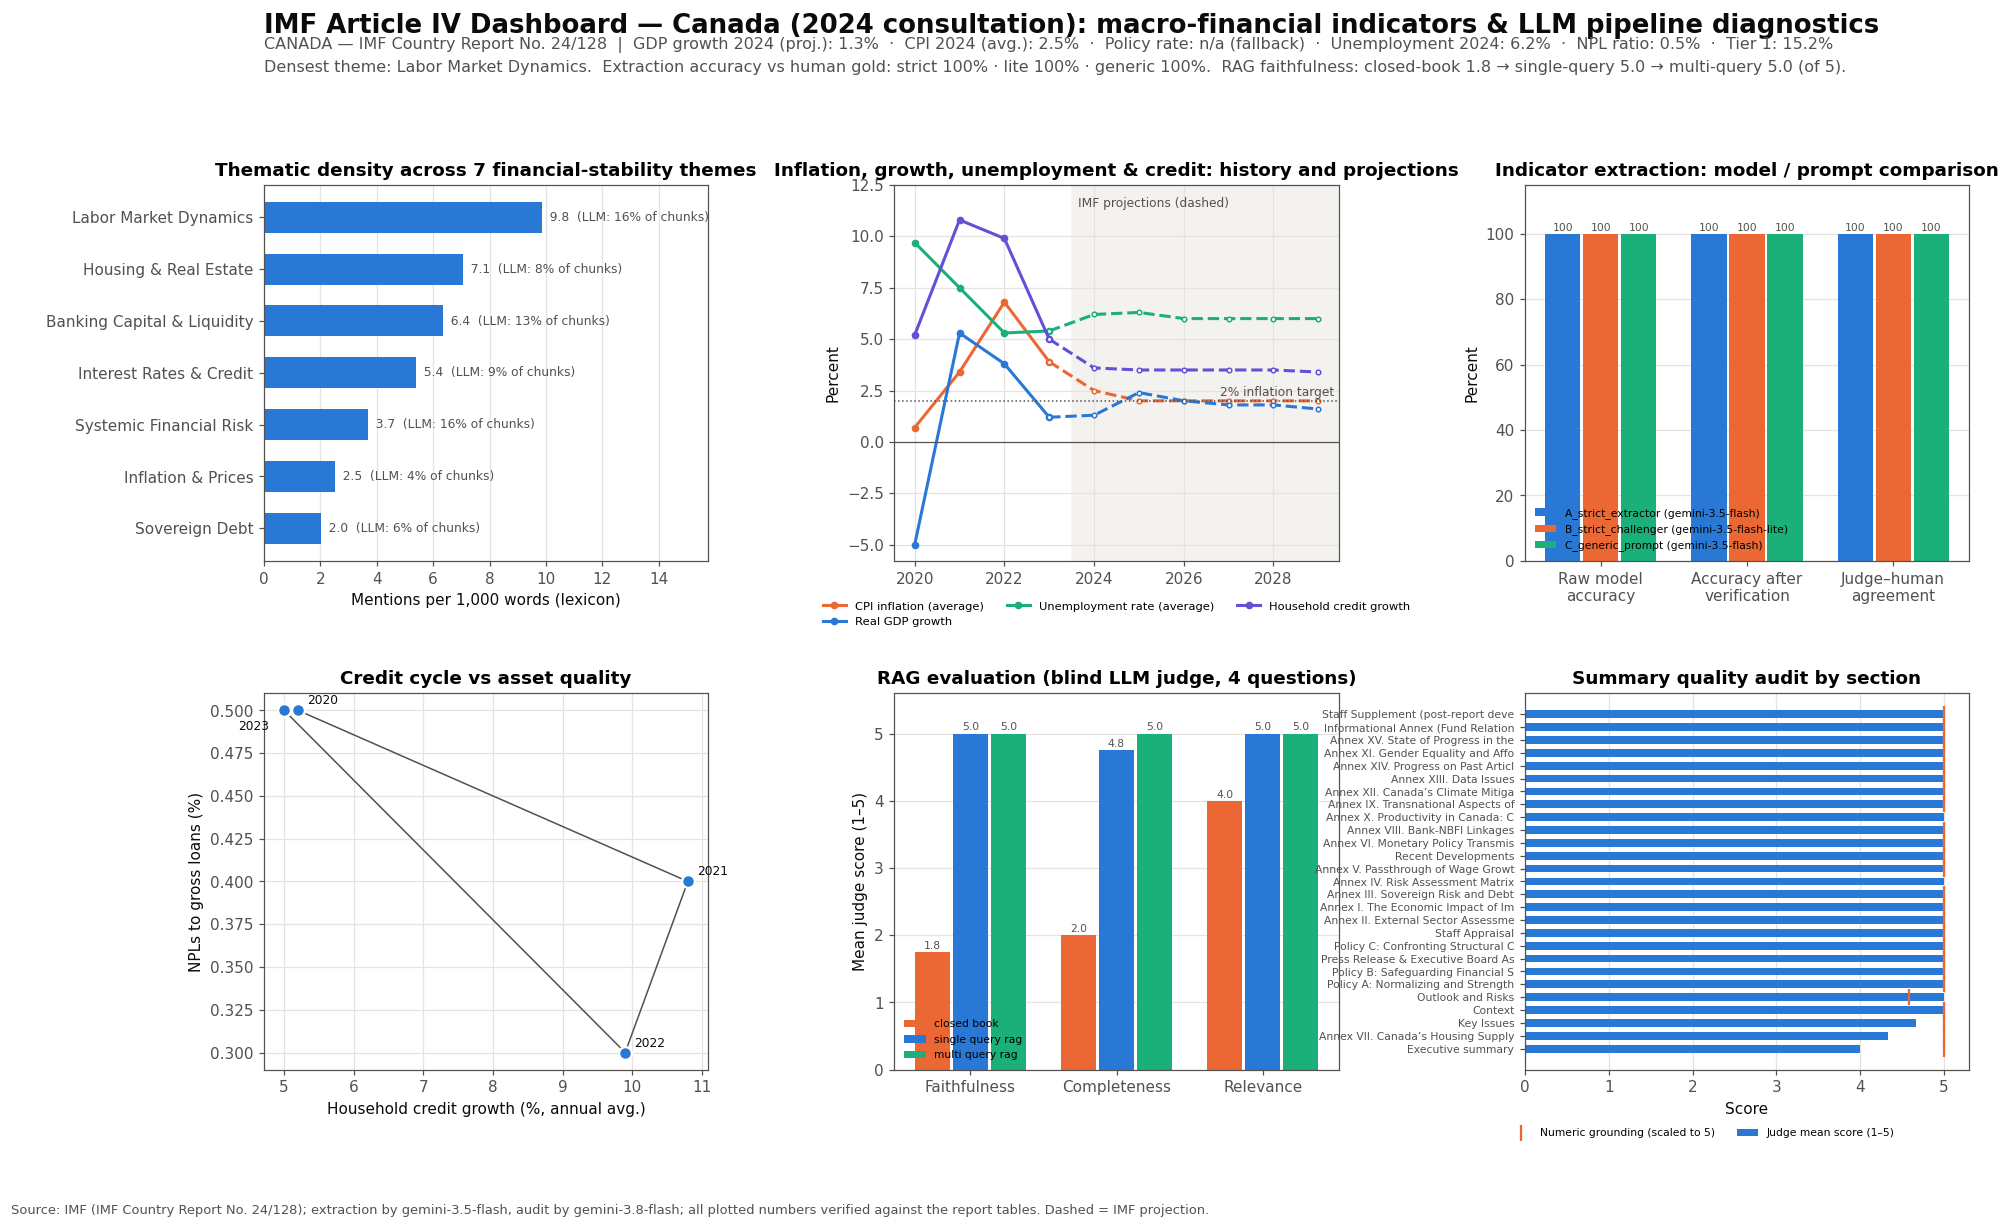

In [29]:
def executive_overlay() -> str:
    fl = final_flat
    fmt = lambda v: "n/a (fallback)" if v is None else f"{v:g}%"
    top_theme = theme_df.sort_values("per_1000_words").theme.iloc[-1]
    acc = BENCH.set_index("config").accuracy_vs_gold_pct
    rag = rag_summary["faithfulness"] if "faithfulness" in rag_summary else pd.Series(dtype=float)
    cy = CFG.consultation_year
    return (f"{CFG.country.upper()} — {CFG.report_id}  |  GDP growth {cy} (proj.): {fmt(fl['gdp_growth_forecast_pct'])}  ·  "
            f"CPI {cy} (avg.): {fmt(fl['headline_inflation_rate_pct'])}  ·  Policy rate: {fmt(fl['central_bank_policy_rate_pct'])}  ·  "
            f"Unemployment {cy}: {fmt(fl['unemployment_rate_pct'])}  ·  NPL ratio: {fmt(fl['non_performing_loan_ratio'])}  ·  "
            f"Tier 1: {fmt(fl['tier_1_capital_ratio'])}\n"
            f"Densest theme: {top_theme}.  Extraction accuracy vs human gold: strict {acc.get('A_strict_extractor', np.nan):.0f}% · "
            f"lite {acc.get('B_strict_challenger', np.nan):.0f}% · generic {acc.get('C_generic_prompt', np.nan):.0f}%.  "
            f"RAG faithfulness: closed-book {rag.get('closed_book', np.nan):.1f} → single-query {rag.get('single_query_rag', np.nan):.1f} "
            f"→ multi-query {rag.get('multi_query_rag', np.nan):.1f} (of 5).")

fig = plt.figure(figsize=(20, 12.5))
gs = fig.add_gridspec(3, 3, height_ratios=[0.11, 1, 1], hspace=0.5, wspace=0.42)
hdr = fig.add_subplot(gs[0, :]); hdr.axis("off")
hdr.text(0, 0.95, f"IMF Article IV Dashboard — {CFG.country} ({CFG.consultation_year} consultation): macro-financial indicators & LLM pipeline diagnostics",
         fontsize=17, fontweight="bold", va="top", color=INK)
hdr.text(0, 0.38, executive_overlay(), fontsize=10.5, va="top", color=MUTED, linespacing=1.6)
for (name, fn), pos in zip(PANELS, [(1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2)]):
    fn(fig.add_subplot(gs[pos]))
fig.text(0.01, 0.005, f"Source: IMF ({CFG.report_id}); extraction by {EXTRACTOR}, audit by {JUDGE}; "
         "all plotted numbers verified against the report tables. Dashed = IMF projection.", fontsize=8.5, color=MUTED)
fig.savefig(FIG_DIR / "dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Run summary
Final integrity checks — the notebook fails loudly here if any required artefact is missing.

In [30]:
REQUIRED_OUTPUTS = ["task1_summaries.json", "core_indicators.json", "task2_indicators_audit.json", "task2_themes.json",
                    "task2_qualitative_insights.json", "task2_trends.json", "task3_rag_evaluation.json", "chunks.jsonl",
                    "figures/dashboard.png"] + [f"figures/{n}.png" for n, _ in PANELS]
missing = [f for f in REQUIRED_OUTPUTS if not (OUT_DIR / f).exists()]
assert not missing, f"Missing outputs: {missing}"
log = pd.DataFrame(LLM.log)
save_json(log.to_dict(orient="records"), "llm_call_log.json")
print(f"All {len(REQUIRED_OUTPUTS)} outputs present.")
print(f"LLM calls this run: {len(log)} ({log.cached.sum()} served from cache, {(~log.cached).sum()} live API calls)")
print(log.groupby(["model"]).agg(calls=("task", "size"), mean_latency_s=("latency_s", "mean")).round(2))

All 15 outputs present.
LLM calls this run: 26 (26 served from cache, 0 live API calls)
                       calls  mean_latency_s
model                                       
gemini-3.5-flash          15           13.48
gemini-3.5-flash-lite      3            4.82
gemini-3.8-flash           8          259.33
